# 07 · Demographics and units: sex, age, weight, country

For anyone checking how Open Altio reads a patient's sex, age, weight and country from FDA's files. Each section asks its questions one at a time, answers each with a chart, and ends with a list, one item per chart: what it shows, its point, and so what. Section 9 says what was decided, in words.

1. Sex: which codes appear and what they mean.
2. Age: units, ages with no unit, the sender's own age group, rounding.
3. Negative ages.
4. The oldest ages and the 122-year cap.
5. One set of age bands for both apps, and babies given as 0 years.
6. Weight: units, the number reader, the 635 kg cap, weights with no unit.
7. Country: the European Union in place of a member state, the member state an earlier version names, the gap the reporter's country fills, `COUNTRY NOT SPECIFIED` and what else is left.
8. Which cases kept change.
9. What was decided.
10. The methods-page cards.

**What it reads.** A release folder built by the command line: `open-altio demo` builds one from FDA's latest quarter, `open-altio build` from every quarter. Point the notebook at it with `OPEN_ALTIO_RELEASE`, or with `RELEASE` in the first code cell. Several sections compare AERS, FDA's system until 2012Q3, with FAERS, so read a release built from every quarter. The notebook reads only FDA's own columns and the derived columns the release holds. Every value as decided is computed here from FDA's columns, so each chart can set the release's value beside the decided one. Everything is read only.

**What it counts.** Cases: one row per case, its latest version, after FDA's deleted lists (`case_latest_T`). A number that counts rows, versions or duplicate groups says so. Every headline number is counted twice, the second time by a separate query on `demo_latest_T` less the cases on FDA's deleted lists, and the notebook stops if the two disagree.

**What does not change.** FDA's values stay exactly as published: `sex`, `age`, `age_cod`, `age_grp`, `wt`, `wt_cod`, `occr_country` and `reporter_country` are never touched. Every value we derive is a separate column whose name ends in `_T`.

**What DiAna does.** DiAna is a FAERS drug dictionary published openly with its cleaning code (`03_standardize_faers.R`). It reads sex as `F` or `M`, else nothing; an age with no unit as years; a negative age as positive; an age over 122 years as none; every age rounded to whole years; a weight with no unit as kilograms; a weight over 635 kg as none; `COUNTRY NOT SPECIFIED` and `A1` as no country. Each section says where the evidence agrees with DiAna and where it does not.

In [1]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from open_altio.faers.insights.cards.notebook import (
    ERA,
    SERIES,
    label_bars,
    mark_quarters,
    out_dir,
    quarter_ticks,
    setup,
    title,
)
from open_altio.faers.insights.source import connect, release_folder

setup(colwidth=90)

# The release this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
SOURCE = release_folder(RELEASE)
TMP = out_dir() / "07_demographics_units" / "tmp"
TMP.mkdir(parents=True, exist_ok=True)
con = connect(SOURCE)  # read only: a view per table of the release
# other jobs share the machine
con.execute(
    f"SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; SET temp_directory = '{TMP}'"
)


def q(sql):
    return con.execute(sql).fetchdf()


def one(sql):
    return con.execute(sql).fetchone()[0]


def drawn(bars):
    """The bars with a length, the only ones worth a label (an empty bar has no place on a log axis)."""
    return [b for b in bars if b.get_width() * b.get_height() > 0]


def say(text):
    """A section's closing list, its numbers computed above."""
    display(Markdown(text))


def pct(part, whole):
    return 100 * part / whole if whole else 0.0


ERA_NAME = {"legacy": "AERS", "faers": "FAERS"}

# Every headline number is counted twice: once on case_latest_T, and once by a second query, written
# separately, on demo_latest_T less the cases on FDA's deleted lists, in either era (the same case set, rebuilt).
SECOND = """(SELECT d.* FROM demo_latest_T d
             WHERE NOT EXISTS (SELECT 1 FROM deleted_cases_T x WHERE x.caseid = d.caseid))"""


def check(label, first, second):
    assert first == second, f"{label}: {first:,} by one query, {second:,} by the other"
    print(f"checked twice: {label} = {first:,}")
    return first


# The rule file each decision lives in; a chart that backs a decision names it.
RULE = {
    "sex": "rules/sex-codes.md",
    "age": "rules/age-in-years.md",
    "bands": "rules/age-bands.md",
    "weight": "rules/weight-in-kg.md",
    "country": "rules/country-not-given.md",
    "eu": "rules/eu-member-state.md",
}


def backs(decision, rule, width=80):
    return textwrap.fill(f"Backs the decision: {decision} ({RULE[rule]}).", width)


# The values as decided, computed from FDA's own columns.
def number(col):
    """A number as the fixed reader reads it: 0.9, .9 and 60. are numbers and spaces around one are
    ignored; a minus sign is not read, so a negative value is no value."""
    return rf"(CASE WHEN regexp_full_match(trim({col}), '[0-9]+\.?[0-9]*|\.[0-9]+') THEN CAST(trim({col}) AS DOUBLE) END)"


YEARS_PER = {
    "YR": 1,
    "DEC": 10,
    "MON": 1 / 12,
    "WK": 7 / 365.25,
    "DY": 1 / 365.25,
    "HR": 1 / 8766,
    "MIN": 1 / 525960,
    "SEC": 1 / 31557600,
}
UNIT_YEARS = (
    "(CASE coalesce(age_cod, 'YR') "
    + " ".join(f"WHEN '{u}' THEN {f!r}" for u, f in YEARS_PER.items())
    + " END)"
)
AGE_ANY = f"({number('age')} * {UNIT_YEARS})"  # an age with no unit is in years; exact, not rounded
AGE_CAP = 122  # the oldest person on record died at 122
AGE_RULED = f"(CASE WHEN {AGE_ANY} <= {AGE_CAP} THEN {AGE_ANY} END)"
ZERO_YEARS = f"({number('age')} = 0 AND coalesce(age_cod, 'YR') IN ('YR', 'DEC'))"  # 0 years: under 1, day unknown


# The reading before the decisions, written out as the release's code read it: a number only as digits
# with an optional decimal part (no .8, 60. or spaces, no minus sign), six units with a week as 1/52.18
# of a year, nothing for an age with no unit or in MIN or SEC, no cap; pounds by 0.45359, zero and any
# weight kept. The charts compare it with the values as decided.
def old_number(col):
    return (
        rf"(CASE WHEN regexp_full_match({col}, '[0-9]+(\.[0-9]+)?') THEN CAST({col} AS DOUBLE) END)"
    )


OLD_AGE = (
    f"(CASE age_cod WHEN 'YR' THEN {old_number('age')} WHEN 'DEC' THEN {old_number('age')} * 10 "
    f"WHEN 'MON' THEN {old_number('age')} / 12 WHEN 'WK' THEN {old_number('age')} / 52.18 "
    f"WHEN 'DY' THEN {old_number('age')} / 365.25 WHEN 'HR' THEN {old_number('age')} / 8766 END)"
)
OLD_WT = (
    f"(CASE WHEN wt_cod IN ('KG', 'KGS') THEN {old_number('wt')} WHEN wt_cod = 'LBS' THEN {old_number('wt')} * 0.45359 "
    f"WHEN wt_cod = 'GMS' THEN {old_number('wt')} / 1000 END)"
)
ZERO_HELD = f"({OLD_AGE} = 0 AND age_cod IN ('YR', 'DEC'))"  # the same, among the ages read before the decisions

YOUNG = ["Under 28 days", "28 days to under 2", "Under 1, exact age not given"]
BANDS = [
    *YOUNG,
    "2 to 11",
    "12 to 17",
    "18 to 64",
    "65 to 74",
    "75 to 84",
    "85 and over",
    "Not given",
]


def band(a, zero):
    """The band of an age in years `a` as decided; `zero` is true for an age given as 0 years, placed
    by the sender's own group (N neonate, I infant) or else as under 1 with the exact age not given."""
    return f"""CASE WHEN {a} IS NULL THEN 'Not given'
                    WHEN {zero} THEN CASE age_grp WHEN 'N' THEN 'Under 28 days' WHEN 'I' THEN '28 days to under 2'
                                                  ELSE 'Under 1, exact age not given' END
                    WHEN {a} < 28 / 365.25 THEN 'Under 28 days' WHEN {a} < 2 THEN '28 days to under 2'
                    WHEN {a} < 12 THEN '2 to 11' WHEN {a} < 18 THEN '12 to 17' WHEN {a} < 65 THEN '18 to 64'
                    WHEN {a} < 75 THEN '65 to 74' WHEN {a} < 85 THEN '75 to 84' ELSE '85 and over' END"""


KG_PER = {"KG": 1, "KGS": 1, "LBS": 0.45359237, "GMS": 0.001}  # pounds by the exact factor
WT_CAP = 635  # the heaviest person on record weighed about 635 kg
WT_ANY = (
    f"({number('wt')} * (CASE wt_cod "
    + " ".join(f"WHEN '{u}' THEN {f!r}" for u, f in KG_PER.items())
    + " END))"
)
WT_RULED = f"(CASE WHEN {WT_ANY} > 0 AND {WT_ANY} <= {WT_CAP} THEN {WT_ANY} END)"
SEX_RULED = "(CASE WHEN sex IN ('F', 'M') THEN sex END)"
NO_COUNTRY = "('COUNTRY NOT SPECIFIED', 'A1')"


def named(col):
    return f"(CASE WHEN {col} NOT IN {NO_COUNTRY} THEN {col} END)"


# a FAERS case's country: the occurrence country, else the reporter's; an AERS case has only the reporter's
COUNTRY_RULED = f"(CASE WHEN era_T = 'faers' THEN coalesce({named('occr_country')}, {named('reporter_country')}) ELSE {named('country_T')} END)"
EU_NAME = "European Union, member state not given"
# the country FDA's two fields give a FAERS case, before the decisions (the release's country_T before them)
FDA_COUNTRY = "coalesce(occr_country, reporter_country)"

# ISO 3166-1 alpha-2: the 249 officially assigned codes
ISO2_CODES = """AD AE AF AG AI AL AM AO AQ AR AS AT AU AW AX AZ BA BB BD BE BF BG BH BI BJ BL BM BN BO BQ BR BS BT BV BW BY BZ CA CC CD CF CG CH CI CK CL CM CN CO CR CU CV CW CX CY CZ DE DJ DK DM DO DZ EC EE EG EH ER ES ET FI FJ FK FM FO FR GA GB GD GE GF GG GH GI GL GM GN GP GQ GR GS GT GU GW GY HK HM HN HR HT HU ID IE IL IM IN IO IQ IR IS IT JE JM JO JP KE KG KH KI KM KN KP KR KW KY KZ LA LB LC LI LK LR LS LT LU LV LY MA MC MD ME MF MG MH MK ML MM MN MO MP MQ MR MS MT MU MV MW MX MY MZ NA NC NE NF NG NI NL NO NP NR NU NZ OM PA PE PF PG PH PK PL PM PN PR PS PT PW PY QA RE RO RS RU RW SA SB SC SD SE SG SH SI SJ SK SL SM SN SO SR SS ST SV SX SY SZ TC TD TF TG TH TJ TK TL TM TN TO TR TT TV TW TZ UA UG UM US UY UZ VA VC VE VG VI VN VU WF WS YE YT ZA ZM ZW"""
ISO2 = set(ISO2_CODES.split())
con.register("iso2_df", pd.DataFrame({"code": sorted(ISO2)}))
EU27 = ["AT", "BE", "BG", "CY", "CZ", "DE", "DK", "EE", "ES", "FI", "FR", "GR", "HR", "HU"]
EU27 += ["IE", "IT", "LT", "LU", "LV", "MT", "NL", "PL", "PT", "RO", "SE", "SI", "SK"]
con.register("eu27_df", pd.DataFrame({"code": EU27}))

N_CASES = check(
    "cases (latest version of each case, after FDA's deleted lists)",
    one("SELECT count(*) FROM case_latest_T"),
    one(f"SELECT count(*) FROM {SECOND}"),
)
N_KEPT = one("SELECT count(*) FROM case_latest_T WHERE dup_kept_T")
print(
    f"Read: {SOURCE.name}. {N_CASES:,} cases, of which {N_KEPT:,} are shown after duplicates are set aside. Every count below is of these cases unless it says otherwise."
)

checked twice: cases (latest version of each case, after FDA's deleted lists) = 20,588,529
Read: 2026Q2-final-v3. 20,588,529 cases, of which 20,296,780 are shown after duplicates are set aside. Every count below is of these cases unless it says otherwise.


## 1. Sex

### Which codes appear, and what does each mean?

FDA's file description lists `F`, `M`, `UNK` (unknown) and `NS` (not specified). The left chart counts each code on the latest version of each case. The right chart shows, quarter by quarter, the share of cases with no sex or an odd code.

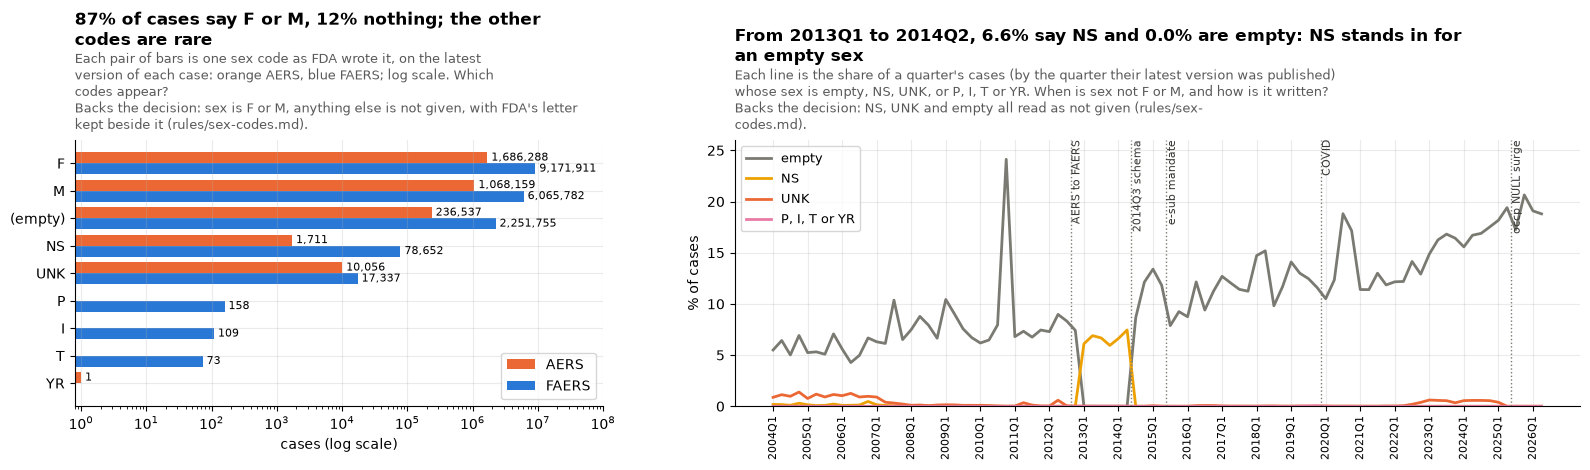

checked twice: cases whose sex is a code other than F or M = 108,097


checked twice: cases with no sex = 2,488,292


checked twice: cases whose sex is not given as decided (not F or M) = 2,596,389


108,097 cases carry a code other than F or M and 2,488,292 carry none; as decided, 2,596,389 cases have no sex. P, I and T: 340 cases, 340 of them direct reports sent through FDA-CTU, published 2019q1 to 2019q4. NS is on 109,401 published rows but 80,363 cases: earlier versions can say NS where the latest says something else.


**What section 1 shows**, one item per chart:

- **Which codes appear.** *Shows:* 87.4% of cases say F or M and 12.1% say nothing. 108,097 carry another code: NS 80,363, UNK 27,393, P, I and T 340 (every one a direct report sent through FDA-CTU in 2019, codes FDA's file description does not define) and 1 YR, a line whose columns slipped. *Point:* beyond F and M the codes say only "not known", in four spellings. *So what:* sex is F or M, anything else is not given (2,596,389 cases), and FDA's own letter stays beside it for anyone who wants UNK apart from empty.
- **When sex is not F or M.** *Shows:* from 2013Q1 to 2014Q2, 6.6% of a quarter's cases say NS and 0.0% are empty; in every other quarter NS averages 0.03% and empty 11.0%. UNK runs at 0.2% to 0.6% from 2022Q3 to 2025Q1, and 0 of the cases published since 2025Q2 say it. *Point:* NS is how FDA wrote an empty sex for six quarters; NS and empty mean the same thing. *So what:* counting only an empty sex as unknown would make 2013 and 2014 look complete; reading NS, UNK and empty alike as not given keeps the share comparable over time. This is one of the methods-page cards.


In [2]:
sx = q(
    """SELECT era_T, coalesce(sex, '(empty)') sex, count(*) cases FROM case_latest_T GROUP BY ALL"""
)
bq = q("""SELECT quarter_T, qnum_T, 100 * avg((sex IS NULL)::INT) "empty", 100 * avg((sex = 'NS')::INT) "NS", 100 * avg((sex = 'UNK')::INT) "UNK",
                 100 * avg((sex NOT IN ('F', 'M', 'NS', 'UNK'))::INT) "P, I, T or YR" FROM case_latest_T GROUP BY 1, 2 ORDER BY 2""")
order = ["F", "M", "(empty)", "NS", "UNK", "P", "I", "T", "YR"]
codes = [o for o in order if o in set(sx.sex)] + sorted(set(sx.sex) - set(order))
piv = sx.pivot(index="sex", columns="era_T", values="cases").reindex(codes).fillna(0)
by_sex = sx.groupby("sex").cases.sum()
window = bq.quarter_T.between("2013q1", "2014q2")
ns_w, em_w = bq[window].NS.mean(), bq[window]["empty"].mean()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
y = np.arange(len(piv))
h = 0.4
for i, era in enumerate(["legacy", "faers"]):
    if era in piv:
        label_bars(
            a1,
            drawn(a1.barh(y + (i - 0.5) * h, piv[era], h, color=ERA[era], label=ERA_NAME[era])),
            horizontal=True,
        )
a1.set_yticks(y)
a1.set_yticklabels(piv.index)
a1.invert_yaxis()
a1.set_xscale("log")
a1.set_xlim(0.8, 1e8)
a1.set_xlabel("cases (log scale)")
a1.legend(loc="lower right")
title(
    a1,
    f"{pct(by_sex['F'] + by_sex['M'], by_sex.sum()):.0f}% of cases say F or M, {pct(by_sex['(empty)'], by_sex.sum()):.0f}% nothing; the other codes are rare",
    "Each pair of bars is one sex code as FDA wrote it, on the latest version of each case: orange AERS, blue FAERS; log scale.",
    "Which codes appear?",
    backs("sex is F or M, anything else is not given, with FDA's letter kept beside it", "sex"),
    width=66,
)
for col, color in [
    ("empty", SERIES[6]),
    ("NS", SERIES[3]),
    ("UNK", SERIES[1]),
    ("P, I, T or YR", SERIES[4]),
]:
    a2.plot(range(len(bq)), bq[col], color=color, label=col)
quarter_ticks(a2, bq.quarter_T)
a2.set_ylim(0, 26)
mark_quarters(a2, bq.quarter_T)
a2.set_ylabel("% of cases")
a2.legend(loc="upper left", fontsize=9)
title(
    a2,
    f"From 2013Q1 to 2014Q2, {ns_w:.1f}% say NS and {em_w:.1f}% are empty: NS stands in for an empty sex",
    "Each line is the share of a quarter's cases (by the quarter their latest version was published) whose sex is empty, NS, UNK, or P, I, T or YR.",
    "When is sex not F or M, and how is it written?",
    backs("NS, UNK and empty all read as not given", "sex"),
    width=100,
)
plt.tight_layout()
plt.show()
odd = check(
    "cases whose sex is a code other than F or M",
    one("SELECT count(*) FROM case_latest_T WHERE sex NOT IN ('F', 'M')"),
    one(f"SELECT count(*) FROM {SECOND} WHERE length(sex) > 0 AND sex <> 'F' AND sex <> 'M'"),
)
empty = check(
    "cases with no sex",
    one("SELECT count(*) FROM case_latest_T WHERE sex IS NULL"),
    one(f"SELECT count(*) - count(sex) FROM {SECOND}"),
)
not_given = check(
    "cases whose sex is not given as decided (not F or M)",
    one(f"SELECT count(*) - count({SEX_RULED}) FROM case_latest_T"),
    one(f"SELECT count(*) FILTER (WHERE coalesce(sex, '') NOT IN ('F', 'M')) FROM {SECOND}"),
)
pit = q("""SELECT count(*) n, count(*) FILTER (WHERE rept_cod = 'DIR' AND mfr_sndr = 'FDA-CTU') direct, min(quarter_T) q0, max(quarter_T) q1
           FROM case_latest_T WHERE sex IN ('P', 'I', 'T')""").iloc[0]
ns_rows = one("SELECT count(*) FROM demo_all WHERE sex = 'NS'")
outside = bq[~window & bq.quarter_T.ge("2004q1")]
unk = bq[bq.quarter_T.between("2022q3", "2025q1")].UNK
unk_late = one("SELECT count(*) FROM case_latest_T WHERE sex = 'UNK' AND qnum_T >= 20252")
print(
    f"{odd:,} cases carry a code other than F or M and {empty:,} carry none; as decided, {not_given:,} cases have no sex. "
    f"P, I and T: {int(pit.n):,} cases, {int(pit.direct):,} of them direct reports sent through FDA-CTU, published {pit.q0} to {pit.q1}. "
    f"NS is on {ns_rows:,} published rows but {by_sex.get('NS', 0):,} cases: earlier versions can say NS where the latest says something else."
)
say(f"""**What section 1 shows**, one item per chart:

- **Which codes appear.** *Shows:* {pct(by_sex["F"] + by_sex["M"], by_sex.sum()):.1f}% of cases say F or M and {pct(empty, N_CASES):.1f}% say nothing. {odd:,} carry another code: NS {by_sex.get("NS", 0):,}, UNK {by_sex.get("UNK", 0):,}, P, I and T {int(pit.n):,} (every one a direct report sent through FDA-CTU in {pit.q0[:4]}, codes FDA's file description does not define) and {by_sex.get("YR", 0):,} YR, a line whose columns slipped. *Point:* beyond F and M the codes say only "not known", in four spellings. *So what:* sex is F or M, anything else is not given ({not_given:,} cases), and FDA's own letter stays beside it for anyone who wants UNK apart from empty.
- **When sex is not F or M.** *Shows:* from 2013Q1 to 2014Q2, {ns_w:.1f}% of a quarter's cases say NS and {em_w:.1f}% are empty; in every other quarter NS averages {outside.NS.mean():.2f}% and empty {outside["empty"].mean():.1f}%. UNK runs at {unk.min():.1f}% to {unk.max():.1f}% from 2022Q3 to 2025Q1, and {unk_late:,} of the cases published since 2025Q2 say it. *Point:* NS is how FDA wrote an empty sex for six quarters; NS and empty mean the same thing. *So what:* counting only an empty sex as unknown would make 2013 and 2014 look complete; reading NS, UNK and empty alike as not given keeps the share comparable over time. This is one of the methods-page cards.
""")

## 2. Age

### Which units appear?

FDA gives an age as a number (`age`) and a unit (`age_cod`): `DEC` decades, `YR` years, `MON` months, `WK` weeks, `DY` days, `HR` hours; FAERS also allows `MIN` and `SEC`. Before the decisions the release's `age_years_T` converted the first six (decades times 10, months over 12, weeks over 52.18, days over 365.25, hours over 8,766). It gave nothing for an age with no unit, an age its number reader did not read, or a negative age; the first code cell writes that reading out, so the charts can set it beside the decisions. The age as decided, computed here, uses the same factors with a week as 7 days of 365.25-day years, and adds minutes and seconds.

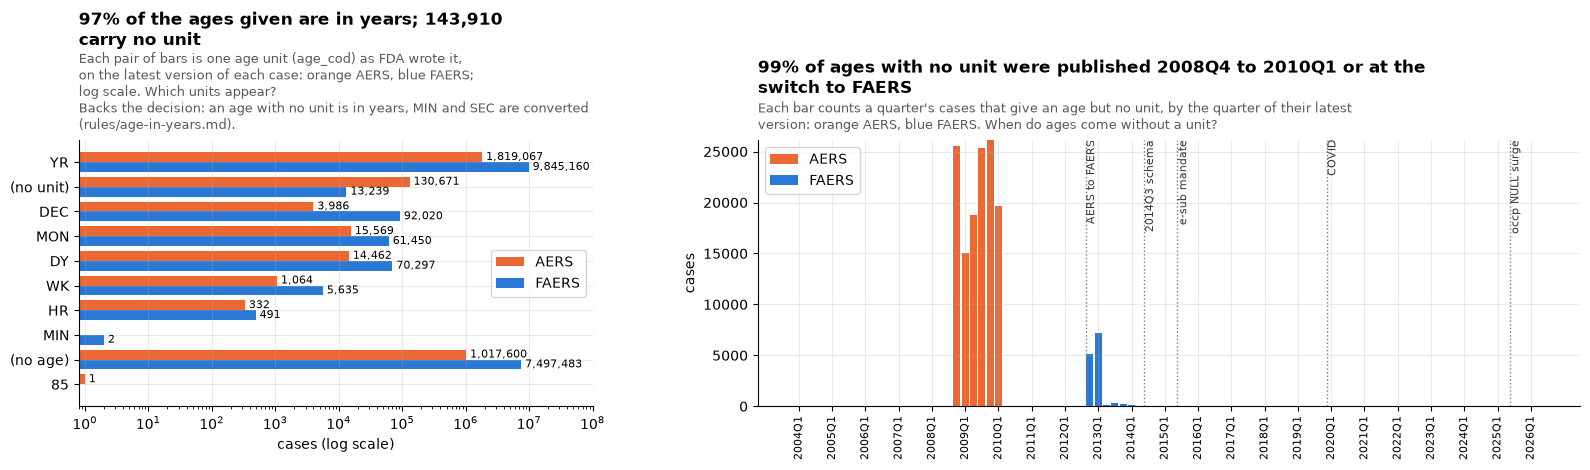

checked twice: cases with an age but no unit = 143,910


checked twice: ages in a known unit that only the fixed number reader reads = 12
143,910 cases give an age with no unit; before the decision the release gave them no age in years. 453,006 cases say YR with no age at all, which is harmless. 13 ages are not numbers (U, FEW, a line whose columns slipped). The fixed number reader adds 12 ages in a known unit, written with a space in front. MIN and SEC: 3 cases, 2 with an age.


In [3]:
au = q(
    """SELECT era_T, CASE WHEN age IS NULL THEN '(no age)' ELSE coalesce(age_cod, '(no unit)') END unit, count(*) cases FROM case_latest_T GROUP BY ALL"""
)
nu = q("""SELECT quarter_T, qnum_T, count(*) FILTER (WHERE age IS NOT NULL AND age_cod IS NULL AND era_T = 'legacy') legacy,
                 count(*) FILTER (WHERE age IS NOT NULL AND age_cod IS NULL AND era_T = 'faers') faers FROM case_latest_T GROUP BY 1, 2 ORDER BY 2""")
order = ["YR", "(no unit)", "DEC", "MON", "DY", "WK", "HR", "MIN", "SEC", "(no age)"]
units = [o for o in order if o in set(au.unit)] + sorted(set(au.unit) - set(order))
piv = au.pivot(index="unit", columns="era_T", values="cases").reindex(units).fillna(0)
given = piv.drop(index="(no age)")
nu["all"] = nu.legacy + nu.faers
clusters = nu.quarter_T.between("2008q4", "2010q1") | nu.quarter_T.between("2012q4", "2013q1")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
y = np.arange(len(piv))
h = 0.4
for i, era in enumerate(["legacy", "faers"]):
    if era in piv:
        label_bars(
            a1,
            drawn(a1.barh(y + (i - 0.5) * h, piv[era], h, color=ERA[era], label=ERA_NAME[era])),
            horizontal=True,
        )
a1.set_yticks(y)
a1.set_yticklabels(piv.index)
a1.invert_yaxis()
a1.set_xscale("log")
a1.set_xlim(0.8, 1e8)
a1.set_xlabel("cases (log scale)")
a1.legend(loc="center right")
title(
    a1,
    f"{pct(given.loc['YR'].sum(), given.values.sum()):.0f}% of the ages given are in years; {int(given.loc['(no unit)'].sum()):,} carry no unit",
    "Each pair of bars is one age unit (age_cod) as FDA wrote it, on the latest version of each case: orange AERS, blue FAERS; log scale.",
    "Which units appear?",
    backs("an age with no unit is in years, MIN and SEC are converted", "age"),
    width=62,
)
a2.bar(range(len(nu)), nu.legacy, color=ERA["legacy"], width=0.85, label="AERS")
a2.bar(range(len(nu)), nu.faers, bottom=nu.legacy, color=ERA["faers"], width=0.85, label="FAERS")
quarter_ticks(a2, nu.quarter_T)
mark_quarters(a2, nu.quarter_T)
a2.set_ylabel("cases")
title(
    a2,
    f"{pct(nu[clusters]['all'].sum(), nu['all'].sum()):.0f}% of ages with no unit were published 2008Q4 to 2010Q1 or at the switch to FAERS",
    "Each bar counts a quarter's cases that give an age but no unit, by the quarter of their latest version: orange AERS, blue FAERS.",
    "When do ages come without a unit?",
    width=100,
)
a2.legend()
plt.tight_layout()
plt.show()
unitless = check(
    "cases with an age but no unit",
    one("SELECT count(*) FROM case_latest_T WHERE age IS NOT NULL AND age_cod IS NULL"),
    one(f"SELECT count(*) FROM {SECOND} WHERE age_cod IS NULL AND length(age) > 0"),
)
yr_no_age = one("SELECT count(*) FROM case_latest_T WHERE age IS NULL AND age_cod = 'YR'")
not_number = one(
    "SELECT count(*) FROM case_latest_T WHERE age IS NOT NULL AND TRY_CAST(age AS DOUBLE) IS NULL"
)
reader = check(
    "ages in a known unit that only the fixed number reader reads",
    one(
        f"SELECT count(*) FROM case_latest_T WHERE {OLD_AGE} IS NULL AND age_cod IN ('YR', 'DEC', 'MON', 'WK', 'DY', 'HR') AND {number('age')} IS NOT NULL"
    ),
    one(
        rf"SELECT count(*) FROM {SECOND} WHERE age_cod IN ('YR', 'DEC', 'MON', 'WK', 'DY', 'HR') AND NOT regexp_full_match(age, '[0-9]+(\.[0-9]+)?') AND regexp_full_match(trim(age), '[0-9]*\.?[0-9]*') AND regexp_matches(age, '[0-9]')"
    ),
)
minsec = q(
    "SELECT age_cod, count(*) cases, count(age) with_an_age FROM case_latest_T WHERE age_cod IN ('MIN', 'SEC') GROUP BY 1"
)
age_grp_unitless = one(
    "SELECT count(*) FROM case_latest_T WHERE age IS NOT NULL AND age_cod IS NULL AND age_grp IS NOT NULL"
)
print(
    f"{unitless:,} cases give an age with no unit; before the decision the release gave them no age in years. {yr_no_age:,} cases say YR with no age at all, which is harmless. "
    f"{not_number:,} ages are not numbers (U, FEW, a line whose columns slipped). The fixed number reader adds {reader:,} ages in a known unit, written with a space in front. "
    f"MIN and SEC: {minsec.cases.sum()} cases, {minsec.with_an_age.sum()} with an age."
)

### Is an age with no unit in years?

DiAna reads it as years. The sender's own age group cannot test it, because almost no unitless age carries one (the group arrived in FAERS in 2014Q3, after nearly all of them). Two other checks do: the spread of the numbers against ages written in years, and, for cases with another version that gives the same number with a unit, which unit that is. A third looks for decades written without their unit, the one way a single-digit age with no unit could hide an adult.

checked twice: unitless ages whose same number another version gives in a unit other than years (borrowing that unit would change them) = 33


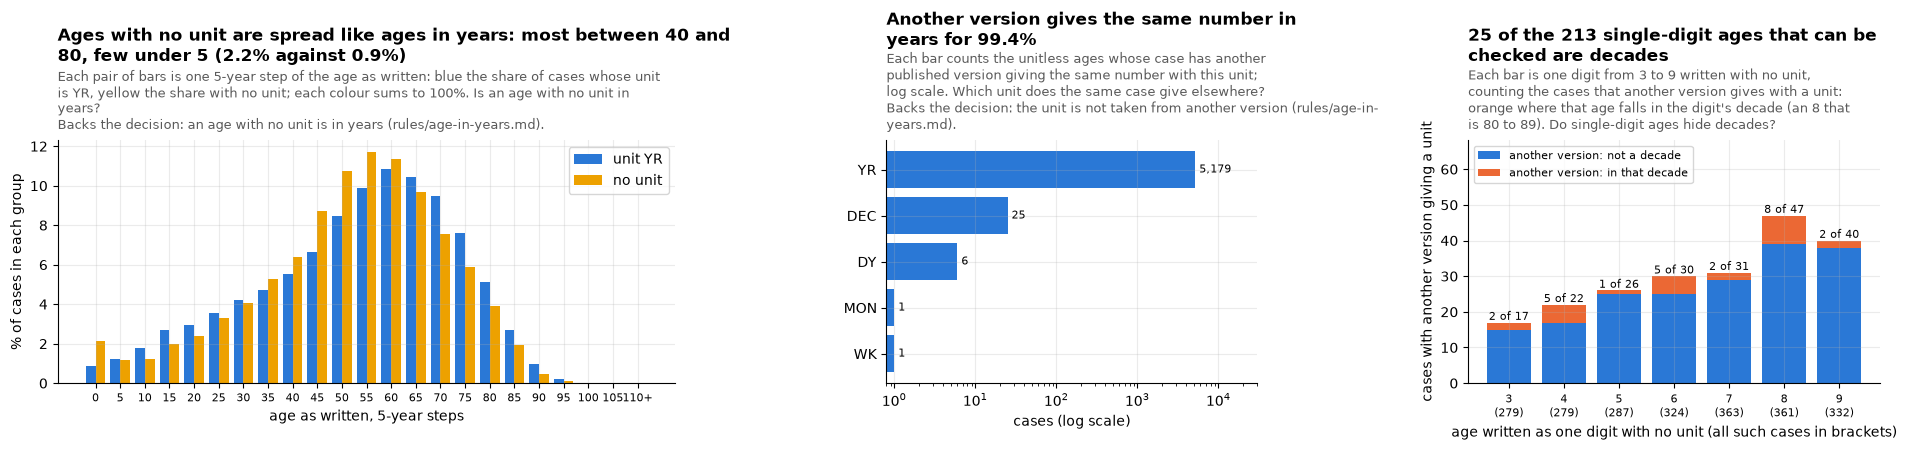

checked twice: unitless ages from 0 to 122 that the decision reads as years = 143,715
5,211 cases with a unitless age have another version giving the same number with a unit; for 5,179 (99.4%) that unit is YR. 33 give it in another unit (DEC 25, DY 6, MON 1, WK 1): the decades are single digits, the days and weeks are zeros, so borrowing would change about 33 ages. Only 6 unitless ages carry the sender's age group.
Single digits 3 to 9 with no unit: 2,225 cases, 213 checkable on another version, 25 of them decades. Of those with a weight, 11% weigh 40 kg or more, against 7% of single-digit ages written in years: a few adults, most children.


In [4]:
A = number("age")
hist = q(f"""SELECT CASE WHEN age_cod IS NULL THEN 'no unit' ELSE 'YR' END k, least(floor({A} / 5) * 5, 110) b, count(*) n
             FROM case_latest_T WHERE {A} IS NOT NULL AND (age_cod IS NULL OR age_cod = 'YR') GROUP BY ALL""")
con.execute(
    """CREATE OR REPLACE TEMP TABLE unitless_T AS SELECT case_key_T, caseid, age, TRY_CAST(age AS DOUBLE) v, wt_kg_T
       FROM case_latest_T WHERE age IS NOT NULL AND age_cod IS NULL AND caseid IS NOT NULL"""
)
ov = q("""SELECT o.age_cod unit, count(DISTINCT x.case_key_T) cases FROM unitless_T x
          JOIN demo_all o ON o.caseid = x.caseid AND o.age = x.age AND o.age_cod IS NOT NULL GROUP BY 1 ORDER BY 2 DESC""")
with_other = one("""SELECT count(DISTINCT x.case_key_T) FROM unitless_T x
                    JOIN demo_all o ON o.caseid = x.caseid AND o.age = x.age AND o.age_cod IS NOT NULL""")
other_unit = check(
    "unitless ages whose same number another version gives in a unit other than years (borrowing that unit would change them)",
    one("""SELECT count(DISTINCT x.case_key_T) FROM unitless_T x
           JOIN demo_all o ON o.caseid = x.caseid AND o.age = x.age AND o.age_cod IS NOT NULL AND o.age_cod <> 'YR'"""),
    one(f"""SELECT count(*) FROM {SECOND} c WHERE c.age_cod IS NULL AND c.age IS NOT NULL
            AND EXISTS (SELECT 1 FROM demo_all o WHERE o.caseid = c.caseid AND o.age = c.age AND o.age_cod <> 'YR')"""),
)
# single digits with no unit: does any version of the same case give an age in years ten times as large (a decade)?
digits = q("""WITH o AS (SELECT x.case_key_T, x.v, TRY_CAST(o.age AS DOUBLE) * CASE o.age_cod WHEN 'YR' THEN 1 WHEN 'DEC' THEN 10 WHEN 'MON' THEN 1 / 12
                                  WHEN 'WK' THEN 7 / 365.25 WHEN 'DY' THEN 1 / 365.25 WHEN 'HR' THEN 1 / 8766 END y
                         FROM unitless_T x JOIN demo_all o ON o.caseid = x.caseid AND o.age_cod IS NOT NULL WHERE x.age IN ('3', '4', '5', '6', '7', '8', '9')),
                   k AS (SELECT case_key_T, bool_or(y >= v * 10 AND y < v * 10 + 10) in_decade FROM o GROUP BY 1)
              SELECT x.v digit, count(*) cases, count(k.case_key_T) checked, count(*) FILTER (WHERE k.in_decade) decades_found
              FROM unitless_T x LEFT JOIN k USING (case_key_T) WHERE x.age IN ('3', '4', '5', '6', '7', '8', '9') GROUP BY 1 ORDER BY 1""")
heavy = q("""SELECT age_cod IS NULL no_unit, count(wt_kg_T) with_weight, 100 * avg((wt_kg_T >= 40)::INT) FILTER (WHERE wt_kg_T IS NOT NULL) heavy
             FROM case_latest_T WHERE age IN ('3', '4', '5', '6', '7', '8', '9') AND (age_cod IS NULL OR age_cod = 'YR') GROUP BY 1""").set_index(
    "no_unit"
)
fig, (a1, a2, a3) = plt.subplots(
    1, 3, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1.5, 0.9, 1]}
)
d = hist.pivot(index="b", columns="k", values="n").fillna(0)
d = 100 * d / d.sum()
x = np.arange(len(d))
w = 0.4
a1.bar(x - w / 2, d["YR"], w, color=SERIES[0], label="unit YR")
a1.bar(x + w / 2, d["no unit"], w, color=SERIES[3], label="no unit")
a1.set_xticks(x)
a1.set_xticklabels([f"{int(b)}" + ("+" if b == 110 else "") for b in d.index], fontsize=8)
a1.set_xlabel("age as written, 5-year steps")
a1.set_ylabel("% of cases in each group")
a1.legend()
under1 = {k: d.loc[0, k] for k in d}
title(
    a1,
    f"Ages with no unit are spread like ages in years: most between 40 and 80, few under 5 ({under1['no unit']:.1f}% against {under1['YR']:.1f}%)",
    "Each pair of bars is one 5-year step of the age as written: blue the share of cases whose unit is YR, yellow the share with no unit; each colour sums to 100%.",
    "Is an age with no unit in years?",
    backs("an age with no unit is in years", "age"),
    width=95,
)
label_bars(a2, drawn(a2.barh(ov.unit[::-1], ov.cases[::-1], color=SERIES[0])), horizontal=True)
a2.set_xscale("log")
a2.set_xlim(0.8, 3e4)
a2.set_xlabel("cases (log scale)")
yr_same = int(ov.set_index("unit").cases.get("YR", 0))
title(
    a2,
    f"Another version gives the same number in years for {pct(yr_same, with_other):.1f}%",
    "Each bar counts the unitless ages whose case has another published version giving the same number with this unit; log scale.",
    "Which unit does the same case give elsewhere?",
    backs("the unit is not taken from another version", "age"),
    width=58,
)
xd = np.arange(len(digits))
a3.bar(
    xd,
    digits.checked - digits.decades_found,
    color=SERIES[0],
    label="another version: not a decade",
)
a3.bar(
    xd,
    digits.decades_found,
    bottom=digits.checked - digits.decades_found,
    color=SERIES[1],
    label="another version: in that decade",
)
for i, r in enumerate(digits.itertuples()):
    a3.text(i, r.checked, f"{r.decades_found} of {r.checked}", ha="center", va="bottom", fontsize=8)
a3.set_xticks(xd)
a3.set_xticklabels([f"{int(r.digit)}\n({r.cases:,})" for r in digits.itertuples()], fontsize=8)
a3.set_xlabel("age written as one digit with no unit (all such cases in brackets)")
a3.set_ylabel("cases with another version giving a unit")
a3.set_ylim(0, digits.checked.max() * 1.45)
a3.legend(fontsize=8, loc="upper left")
title(
    a3,
    f"{int(digits.decades_found.sum())} of the {int(digits.checked.sum())} single-digit ages that can be checked are decades",
    "Each bar is one digit from 3 to 9 written with no unit, counting the cases that another version gives with a unit: orange where that age falls in the digit's decade (an 8 that is 80 to 89).",
    "Do single-digit ages hide decades?",
    width=62,
)
plt.tight_layout()
plt.show()
gain = check(
    "unitless ages from 0 to 122 that the decision reads as years",
    one(f"SELECT count(*) FROM case_latest_T WHERE age_cod IS NULL AND {AGE_RULED} IS NOT NULL"),
    one(
        f"SELECT count(*) FROM {SECOND} WHERE age_cod IS NULL AND TRY_CAST(trim(age) AS DOUBLE) BETWEEN 0 AND {AGE_CAP} AND NOT starts_with(trim(age), '-')"
    ),
)
nonyr = ov[ov.unit != "YR"].set_index("unit").cases
print(
    f"{with_other:,} cases with a unitless age have another version giving the same number with a unit; for {yr_same:,} ({pct(yr_same, with_other):.1f}%) that unit is YR. "
    f"{other_unit} give it in another unit ({', '.join(f'{u} {n}' for u, n in nonyr.items())}): the decades are single digits, the days and weeks are zeros, so borrowing would change about {other_unit} ages. "
    f"Only {age_grp_unitless} unitless ages carry the sender's age group."
)
print(
    f"Single digits 3 to 9 with no unit: {int(digits.cases.sum()):,} cases, {int(digits.checked.sum())} checkable on another version, {int(digits.decades_found.sum())} of them decades. "
    f"Of those with a weight, {heavy.heavy[True]:.0f}% weigh 40 kg or more, against {heavy.heavy[False]:.0f}% of single-digit ages written in years: a few adults, most children."
)

### Do the conversions agree with the sender's own age group?

Since 2014Q3 FAERS has `age_grp`, the sender's own group for the patient (`N` neonate, `I` infant, `C` child, `T` adolescent, `A` adult, `E` elderly). The sender sets the edges, so it is not a perfect yardstick, but it is written apart from `age` and `age_cod`, so it tests the unit conversions. Decades need their own look: an age is often given as "in their sixties", so `6 DEC` could mean 60 to 69.

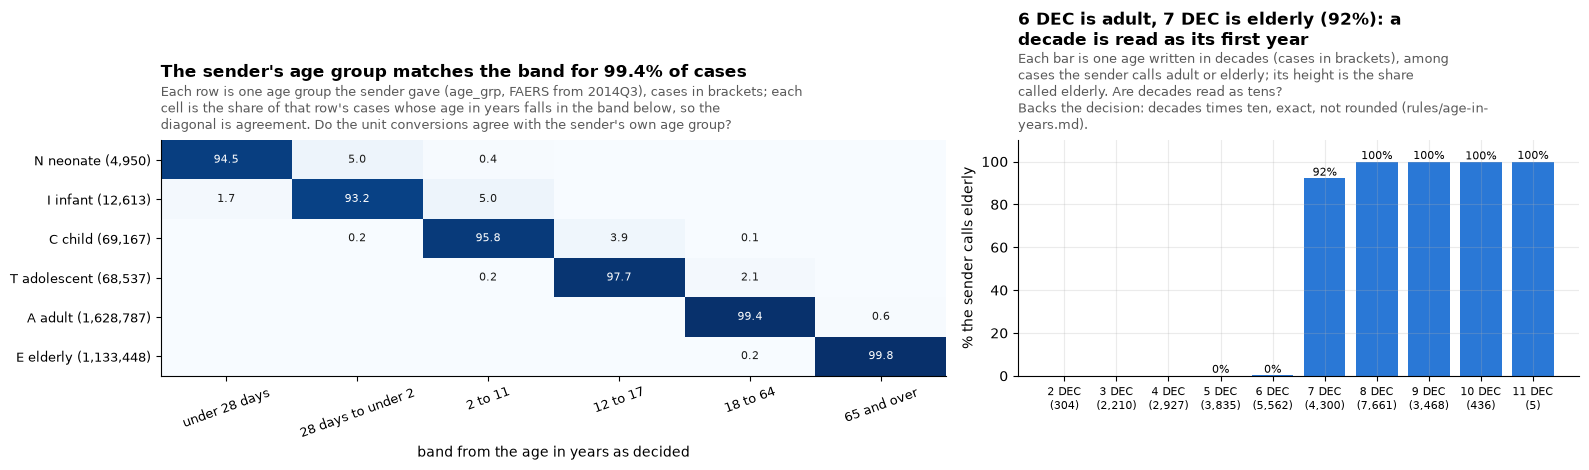

checked twice: cases with an age in years as decided and the sender's age group = 2,917,502
2,917,502 cases give both an age and the sender's age group. The group matches the band for 99.4% of them, and for at least 91% in every unit with 100 cases or more. Ages in decades: 48% come from Japan and 34% from the United States.


In [5]:
BAND6 = """CASE WHEN a < 28 / 365.25 THEN 'under 28 days' WHEN a < 2 THEN '28 days to under 2' WHEN a < 12 THEN '2 to 11'
               WHEN a < 18 THEN '12 to 17' WHEN a < 65 THEN '18 to 64' ELSE '65 and over' END"""
ag = q(f"""SELECT unit, age_grp, {BAND6} band, count(*) cases
           FROM (SELECT coalesce(age_cod, '(no unit)') unit, age_grp, {AGE_RULED} a FROM case_latest_T WHERE age_grp IN ('N', 'I', 'C', 'T', 'A', 'E'))
           WHERE a IS NOT NULL GROUP BY ALL""")
GRP = {"N": "neonate", "I": "infant", "C": "child", "T": "adolescent", "A": "adult", "E": "elderly"}
MATCH = {
    "N": "under 28 days",
    "I": "28 days to under 2",
    "C": "2 to 11",
    "T": "12 to 17",
    "A": "18 to 64",
    "E": "65 and over",
}
heat = (
    ag.pivot_table(index="age_grp", columns="band", values="cases", aggfunc="sum")
    .reindex(index=list(GRP), columns=list(MATCH.values()))
    .fillna(0)
)
share = 100 * heat.div(heat.sum(axis=1), axis=0)
ag["agree"] = [MATCH[g] == b for g, b in zip(ag.age_grp, ag.band, strict=True)]
by_unit = ag.groupby("unit").apply(
    lambda d: pct(d[d.agree].cases.sum(), d.cases.sum()), include_groups=False
)
by_unit_n = ag.groupby("unit").cases.sum()
dec = (
    q("""SELECT TRY_CAST(age AS DOUBLE) AS n_decades, age_grp, count(*) cases FROM case_latest_T
           WHERE age_cod = 'DEC' AND age_grp IN ('A', 'E') AND TRY_CAST(age AS DOUBLE) BETWEEN 2 AND 11 GROUP BY ALL""")
    .pivot(index="n_decades", columns="age_grp", values="cases")
    .fillna(0)
)
dec_c = q(
    "SELECT coalesce(country_T, '(none)') c, count(*) n FROM case_latest_T WHERE age_cod = 'DEC' GROUP BY 1 ORDER BY 2 DESC"
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
a1.imshow(share.values, cmap="Blues", aspect="auto", vmin=0, vmax=100)
a1.grid(False)
a1.set_xticks(range(len(share.columns)))
a1.set_xticklabels(share.columns, rotation=20, fontsize=9)
a1.set_yticks(range(len(share.index)))
a1.set_yticklabels([f"{g} {GRP[g]} ({int(heat.loc[g].sum()):,})" for g in share.index], fontsize=9)
for (i, j), v in np.ndenumerate(share.values):
    if v >= 0.05:
        a1.text(
            j,
            i,
            f"{v:.1f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if v > 60 else "#1a1a19",
        )
a1.set_xlabel("band from the age in years as decided")
title(
    a1,
    f"The sender's age group matches the band for {pct(ag[ag.agree].cases.sum(), ag.cases.sum()):.1f}% of cases",
    "Each row is one age group the sender gave (age_grp, FAERS from 2014Q3), cases in brackets; each cell is the share of that row's cases whose age in years "
    "falls in the band below, so the diagonal is agreement.",
    "Do the unit conversions agree with the sender's own age group?",
    width=95,
)
x = np.arange(len(dec))
label_bars(a2, drawn(a2.bar(x, 100 * dec["E"] / dec.sum(axis=1), color=SERIES[0])), "{:.0f}%")
a2.set_xticks(x)
a2.set_xticklabels(
    [f"{int(v)} DEC\n({int(n):,})" for v, n in zip(dec.index, dec.sum(axis=1), strict=True)],
    fontsize=8,
)
a2.set_ylim(0, 110)
a2.set_ylabel("% the sender calls elderly")
title(
    a2,
    f"6 DEC is adult, 7 DEC is elderly ({pct(dec.loc[7, 'E'], dec.loc[7].sum()):.0f}%): a decade is read as its first year",
    "Each bar is one age written in decades (cases in brackets), among cases the sender calls adult or elderly; its height is the share called elderly.",
    "Are decades read as tens?",
    backs("decades times ten, exact, not rounded", "age"),
    width=66,
)
plt.tight_layout()
plt.show()
tot = check(
    "cases with an age in years as decided and the sender's age group",
    int(ag.cases.sum()),
    one(
        f"SELECT count(*) FROM {SECOND} WHERE {AGE_RULED} IS NOT NULL AND age_grp IN ('N', 'I', 'C', 'T', 'A', 'E')"
    ),
)
dc = dec_c.set_index("c").n
print(
    f"{tot:,} cases give both an age and the sender's age group. The group matches the band for {pct(ag[ag.agree].cases.sum(), tot):.1f}% of them, "
    f"and for at least {by_unit[by_unit_n >= 100].min():.0f}% in every unit with 100 cases or more. "
    f"Ages in decades: {pct(dc.get('JP', 0), dc.sum()):.0f}% come from Japan and {pct(dc.get('US', 0), dc.sum()):.0f}% from the United States."
)

### Should ages be rounded to whole years?

DiAna turns every age into days, rounds, then rounds again to whole years. The age in years as decided keeps the fraction (18 months is 1.5). The difference matters only at a band edge.

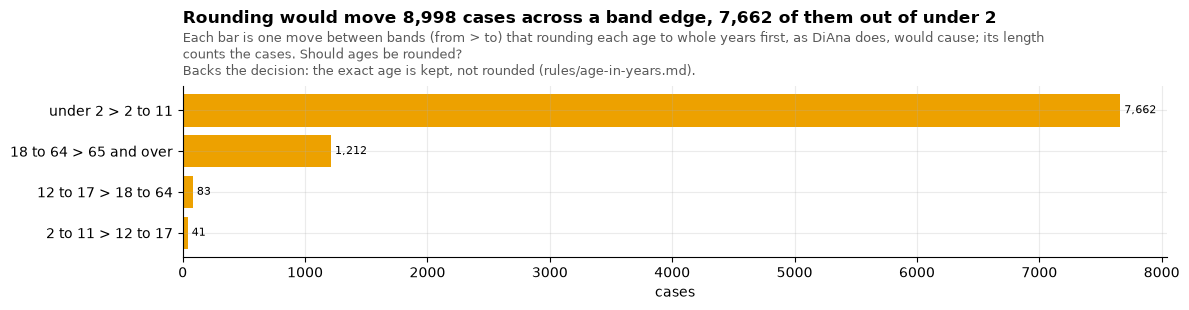

checked twice: cases that change band when rounded = 8,998
Rounding moves 8,998 cases across a band edge: 7,662 children aged 1.5 to 2 go into '2 to 11' and 1,212 adults just under 65 go into '65 and over'.


**What section 2 shows**, one item per chart:

- **Which units appear.** *Shows:* 97% of the ages given are in years; 143,910 carry no unit, more than every unit but years; MIN and SEC hold 2 ages. *Point:* the unitless ages are the one large group the release leaves without an age. *So what:* an age with no unit is read as years and MIN and SEC are converted; the fixed number reader adds 12 ages written with a space.
- **When ages come without a unit.** *Shows:* 99% were published 2008Q4 to 2010Q1 or 2012Q4 to 2013Q1, the months around the switch to FAERS. *Point:* a gap in how two systems wrote the unit, not a kind of patient. *So what:* reading them as years fills an old hole without touching recent quarters.
- **Spread against ages in years.** *Shows:* the unitless ages follow the shape of ages in years, most between 40 and 80, 2.2% under 5 against 0.9%. *Point:* they look like years, not months or decades. *So what:* backs reading them as years.
- **The unit another version gives.** *Shows:* of 5,211 unitless ages whose case gives the same number with a unit elsewhere, 99.4% say YR; 33 say another unit, mostly single-digit decades and zero days. *Point:* where it can be tested, years is right; the exceptions are about 33 cases. *So what:* the unit is not borrowed from another version: about 33 cases, not worth a rule.
- **Decades hidden in single digits.** *Shows:* 2,225 unitless ages are one digit from 3 to 9; 213 can be checked on another version and 25 of those are decades; 11% of those with a weight weigh 40 kg or more, against 7% of single digits written in years. *Point:* a few are adults given in decades, most are children, and nothing tells which. *So what:* too few to read differently; they stay years.
- **The sender's age group against the band.** *Shows:* the group matches the band for 99.4% of 2,917,502 cases, at least 91% in every unit with 100 cases or more; the misses sit at the edges. Only 6 unitless ages carry a group. *Point:* the conversions are right; this check cannot test the unitless ages, the spread and the other versions do. *So what:* the conversion factors stay.
- **Decades as tens.** *Shows:* senders call 6 DEC adult and 7 DEC elderly; 48% of decade ages come from Japan and 34% from the United States. *Point:* 6 DEC is 60, the bottom of the decade. *So what:* decades stay times ten.
- **Rounding.** *Shows:* rounding to whole years would move 8,998 cases across a band edge, 7,662 of them out of under 2. *Point:* rounding gains nothing, since bands work on the exact age, and it costs the band paediatric safety watches most. *So what:* the exact age is kept, not rounded.


In [6]:
# DiAna (03_standardize_faers.R): days = round(|age| * factor), years = round(days / 365); R rounds half to even
DAYS = "CASE coalesce(age_cod, 'YR') WHEN 'DEC' THEN 3650 WHEN 'YR' THEN 365 WHEN 'MON' THEN 30.4375 WHEN 'WK' THEN 7 WHEN 'DY' THEN 1 WHEN 'HR' THEN 1 / 24 END"
rd = q(f"""WITH a AS (SELECT {AGE_RULED} y, {number("age")} * {DAYS} AS days FROM case_latest_T),
               b AS (SELECT y, round_even(round_even(days, 0) / 365, 0) r FROM a WHERE y IS NOT NULL AND days IS NOT NULL)
          SELECT CASE WHEN y < 2 THEN 0 WHEN y < 12 THEN 1 WHEN y < 18 THEN 2 WHEN y < 65 THEN 3 ELSE 4 END e,
                 CASE WHEN r < 2 THEN 0 WHEN r < 12 THEN 1 WHEN r < 18 THEN 2 WHEN r < 65 THEN 3 ELSE 4 END f, count(*) cases
          FROM b GROUP BY ALL""")
NAMES = ["under 2", "2 to 11", "12 to 17", "18 to 64", "65 and over"]
moved = rd[rd.e != rd.f].copy()
moved["move"] = [f"{NAMES[e]} > {NAMES[f]}" for e, f in zip(moved.e, moved.f, strict=True)]
moved = moved.sort_values("cases")
big = moved.set_index("move").cases
fig, ax = plt.subplots(figsize=(12, 3.2))
label_bars(ax, drawn(ax.barh(moved.move, moved.cases, color=SERIES[3])), horizontal=True)
ax.set_xlabel("cases")
title(
    ax,
    f"Rounding would move {int(moved.cases.sum()):,} cases across a band edge, {int(big.get('under 2 > 2 to 11', 0)):,} of them out of under 2",
    "Each bar is one move between bands (from > to) that rounding each age to whole years first, as DiAna does, would cause; its length counts the cases.",
    "Should ages be rounded?",
    backs("the exact age is kept, not rounded", "age"),
    width=134,
)
plt.tight_layout()
plt.show()
raw = q(
    f"SELECT age, coalesce(age_cod, 'YR') age_cod, count(*) cases FROM case_latest_T WHERE {AGE_RULED} IS NOT NULL AND age_cod IN ('YR', 'DEC', 'MON', 'WK', 'DY', 'HR') OR (age_cod IS NULL AND {AGE_RULED} IS NOT NULL) GROUP BY ALL"
)  # recomputed in Python
num = raw.age.str.strip().astype(float)
exact = num * raw.age_cod.map(YEARS_PER)
dia = np.round(
    np.round(
        num
        * raw.age_cod.map({"YR": 365, "DEC": 3650, "MON": 30.4375, "WK": 7, "DY": 1, "HR": 1 / 24})
    )
    / 365
)  # numpy rounds half to even, as R
edges = [2, 12, 18, 65]
n_moved = check(
    "cases that change band when rounded",
    int(moved.cases.sum()),
    int(
        raw.cases[
            np.searchsorted(edges, exact, side="right") != np.searchsorted(edges, dia, side="right")
        ].sum()
    ),
)
print(
    f"Rounding moves {n_moved:,} cases across a band edge: {big.get('under 2 > 2 to 11', 0):,} children aged 1.5 to 2 go into '2 to 11' "
    f"and {big.get('18 to 64 > 65 and over', 0):,} adults just under 65 go into '65 and over'."
)
say(f"""**What section 2 shows**, one item per chart:

- **Which units appear.** *Shows:* {pct(given.loc["YR"].sum(), given.values.sum()):.0f}% of the ages given are in years; {unitless:,} carry no unit, more than every unit but years; MIN and SEC hold {minsec.with_an_age.sum()} ages. *Point:* the unitless ages are the one large group the release leaves without an age. *So what:* an age with no unit is read as years and MIN and SEC are converted; the fixed number reader adds {reader} ages written with a space.
- **When ages come without a unit.** *Shows:* {pct(nu[clusters]["all"].sum(), nu["all"].sum()):.0f}% were published 2008Q4 to 2010Q1 or 2012Q4 to 2013Q1, the months around the switch to FAERS. *Point:* a gap in how two systems wrote the unit, not a kind of patient. *So what:* reading them as years fills an old hole without touching recent quarters.
- **Spread against ages in years.** *Shows:* the unitless ages follow the shape of ages in years, most between 40 and 80, {under1["no unit"]:.1f}% under 5 against {under1["YR"]:.1f}%. *Point:* they look like years, not months or decades. *So what:* backs reading them as years.
- **The unit another version gives.** *Shows:* of {with_other:,} unitless ages whose case gives the same number with a unit elsewhere, {pct(yr_same, with_other):.1f}% say YR; {other_unit} say another unit, mostly single-digit decades and zero days. *Point:* where it can be tested, years is right; the exceptions are about {other_unit} cases. *So what:* the unit is not borrowed from another version: about {other_unit} cases, not worth a rule.
- **Decades hidden in single digits.** *Shows:* {int(digits.cases.sum()):,} unitless ages are one digit from 3 to 9; {int(digits.checked.sum())} can be checked on another version and {int(digits.decades_found.sum())} of those are decades; {heavy.heavy[True]:.0f}% of those with a weight weigh 40 kg or more, against {heavy.heavy[False]:.0f}% of single digits written in years. *Point:* a few are adults given in decades, most are children, and nothing tells which. *So what:* too few to read differently; they stay years.
- **The sender's age group against the band.** *Shows:* the group matches the band for {pct(ag[ag.agree].cases.sum(), tot):.1f}% of {tot:,} cases, at least {by_unit[by_unit_n >= 100].min():.0f}% in every unit with 100 cases or more; the misses sit at the edges. Only {age_grp_unitless} unitless ages carry a group. *Point:* the conversions are right; this check cannot test the unitless ages, the spread and the other versions do. *So what:* the conversion factors stay.
- **Decades as tens.** *Shows:* senders call 6 DEC adult and 7 DEC elderly; {pct(dc.get("JP", 0), dc.sum()):.0f}% of decade ages come from Japan and {pct(dc.get("US", 0), dc.sum()):.0f}% from the United States. *Point:* 6 DEC is 60, the bottom of the decade. *So what:* decades stay times ten.
- **Rounding.** *Shows:* rounding to whole years would move {n_moved:,} cases across a band edge, {big.get("under 2 > 2 to 11", 0):,} of them out of under 2. *Point:* rounding gains nothing, since bands work on the exact age, and it costs the band paediatric safety watches most. *So what:* the exact age is kept, not rounded.
""")

## 3. Negative ages

### What does a negative age mean?

DiAna makes a negative age positive, so `-1 YR` becomes a 1-year-old. The release reads it as no age. The charts show which numbers appear and what the cases are about.

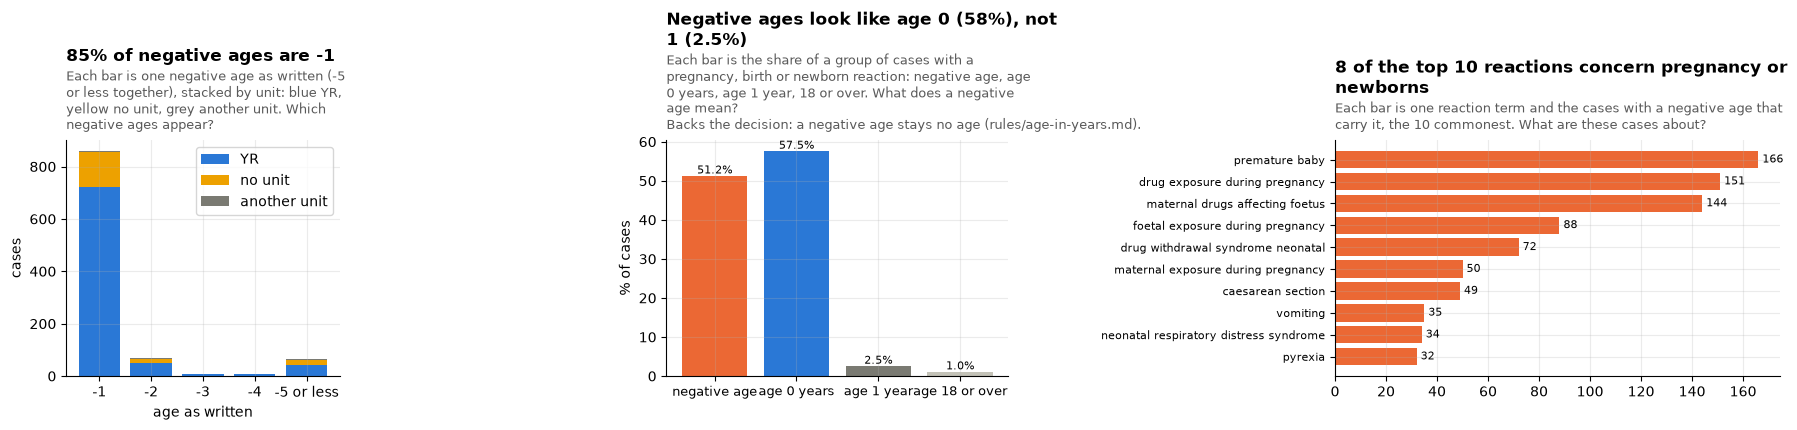

checked twice: cases with a negative age = 1,012
1,012 cases have a negative age: 828 in years, 171 with no unit, 13 in another unit; 858 say -1 and 95% are AERS cases. 51% carry a pregnancy, birth or newborn reaction, like cases aged 0 (58%) and unlike cases aged 1 (2.5%) or adults (1.0%).


**What section 3 shows**, one item per chart:

- **Which negative ages appear.** *Shows:* 1,012 cases, 85% of them -1; 828 in years and 171 with no unit; 95% are AERS cases. *Point:* a way of writing the age in AERS, nearly always -1, not typing slips spread over all values. *So what:* small enough to leave as no age.
- **What a negative age means.** *Shows:* 51% of these cases carry a pregnancy, birth or newborn reaction, like cases aged 0 (58%) and unlike cases aged 1 (2.5%) or adults (1.0%). *Point:* a negative age marks a child exposed before birth, not a 1-year-old; ICH E2B(R3)'s own list of age groups starts with "foetus". *So what:* a negative age stays no age; made positive, as DiAna does, about a thousand exposures before birth would count as toddlers.
- **What these cases are about.** *Shows:* 8 of the 10 commonest reactions concern pregnancy or newborns: premature baby, drug exposure during pregnancy, maternal drugs affecting foetus, foetal exposure during pregnancy. *Point:* the same story, read from the reactions. *So what:* the methods page says why a negative age is no age.


In [7]:
neg = q("""SELECT era_T, TRY_CAST(age AS DOUBLE) v, CASE WHEN age_cod IS NULL THEN 'no unit' WHEN age_cod = 'YR' THEN 'YR' ELSE 'another unit' END unit,
                  count(*) cases FROM case_latest_T WHERE TRY_CAST(age AS DOUBLE) < 0 GROUP BY ALL""")
PREG = "regexp_matches(lower(pt), 'pregnan|foet|fetal|neonat|premature baby|maternal|newborn|caesarean|congenital|small for dates|birth')"
pr = q(f"""WITH c AS (SELECT era_T, primaryid, quarter_T,
                  CASE WHEN TRY_CAST(age AS DOUBLE) < 0 THEN 'negative age' WHEN {ZERO_YEARS} THEN 'age 0 years'
                       WHEN {AGE_RULED} = 1 AND coalesce(age_cod, 'YR') = 'YR' THEN 'age 1 year' WHEN {AGE_RULED} >= 18 THEN 'age 18 or over' END grp
                  FROM case_latest_T),
            f AS (SELECT DISTINCT era_T, primaryid, quarter_T FROM reac_latest_T WHERE {PREG})
       SELECT grp, count(*) cases, count(f.primaryid) with_term FROM c LEFT JOIN f USING (era_T, primaryid, quarter_T) WHERE grp IS NOT NULL GROUP BY 1""")
pr = pr.set_index("grp").reindex(["negative age", "age 0 years", "age 1 year", "age 18 or over"])
top = q("""SELECT lower(r.pt) pt, count(DISTINCT c.case_key_T) cases FROM case_latest_T c JOIN reac_latest_T r USING (era_T, primaryid, quarter_T)
            WHERE TRY_CAST(c.age AS DOUBLE) < 0 GROUP BY 1 ORDER BY 2 DESC, 1 LIMIT 10""")
fig, (a1, a2, a3) = plt.subplots(
    1, 3, figsize=(18, 4.4), gridspec_kw={"width_ratios": [0.8, 1, 1.3]}
)
nv = (
    neg.assign(v=neg.v.clip(lower=-5))
    .groupby(["v", "unit"])
    .cases.sum()
    .unstack()
    .fillna(0)
    .sort_index(ascending=False)
)
bottom = np.zeros(len(nv))
for unit, color in [("YR", SERIES[0]), ("no unit", SERIES[3]), ("another unit", SERIES[6])]:
    if unit in nv:
        a1.bar(range(len(nv)), nv[unit], bottom=bottom, color=color, label=unit)
        bottom += nv[unit].values
a1.set_xticks(range(len(nv)))
a1.set_xticklabels([f"{int(v)}" if v > -5 else "-5 or less" for v in nv.index])
a1.set_xlabel("age as written")
a1.set_ylabel("cases")
a1.legend()
title(
    a1,
    f"{pct(neg[neg.v == -1].cases.sum(), neg.cases.sum()):.0f}% of negative ages are -1",
    "Each bar is one negative age as written (-5 or less together), stacked by unit: blue YR, yellow no unit, grey another unit.",
    "Which negative ages appear?",
    width=44,
)
rate = 100 * pr.with_term / pr.cases
label_bars(
    a2,
    drawn(a2.bar(rate.index, rate, color=[SERIES[1], SERIES[0], SERIES[6], SERIES[7]])),
    "{:.1f}%",
)
a2.set_ylabel("% of cases")
a2.tick_params(axis="x", labelsize=9)
title(
    a2,
    f"Negative ages look like age 0 ({rate['age 0 years']:.0f}%), not 1 ({rate['age 1 year']:.1f}%)",
    "Each bar is the share of a group of cases with a pregnancy, birth or newborn reaction: negative age, age 0 years, age 1 year, 18 or over.",
    "What does a negative age mean?",
    backs("a negative age stays no age", "age"),
    width=56,
)
label_bars(a3, drawn(a3.barh(top.pt[::-1], top.cases[::-1], color=SERIES[1])), horizontal=True)
n_preg = int(
    top.pt.str.contains(
        "pregnan|foet|fetal|neonat|premature baby|maternal|newborn|caesarean|congenital|small for dates|birth"
    ).sum()
)
title(
    a3,
    f"{n_preg} of the top {len(top)} reactions concern pregnancy or newborns",
    "Each bar is one reaction term and the cases with a negative age that carry it, the 10 commonest.",
    "What are these cases about?",
    width=72,
)
a3.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
n_neg = check(
    "cases with a negative age",
    one("SELECT count(*) FROM case_latest_T WHERE TRY_CAST(age AS DOUBLE) < 0"),
    one(
        f"SELECT count(*) FROM {SECOND} WHERE starts_with(age, '-') AND TRY_CAST(age AS DOUBLE) IS NOT NULL"
    ),
)
nu_ = neg.groupby("unit").cases.sum()
m1 = int(neg[neg.v == -1].cases.sum())
legacy_neg = int(neg[neg.era_T == "legacy"].cases.sum())
print(
    f"{n_neg:,} cases have a negative age: {nu_.get('YR', 0):,} in years, {nu_.get('no unit', 0):,} with no unit, {nu_.get('another unit', 0):,} in another unit; "
    f"{m1:,} say -1 and {pct(legacy_neg, n_neg):.0f}% are AERS cases. {rate['negative age']:.0f}% carry a pregnancy, birth or newborn reaction, "
    f"like cases aged 0 ({rate['age 0 years']:.0f}%) and unlike cases aged 1 ({rate['age 1 year']:.1f}%) or adults ({rate['age 18 or over']:.1f}%)."
)
say(f"""**What section 3 shows**, one item per chart:

- **Which negative ages appear.** *Shows:* {n_neg:,} cases, {pct(m1, n_neg):.0f}% of them -1; {nu_.get("YR", 0):,} in years and {nu_.get("no unit", 0):,} with no unit; {pct(legacy_neg, n_neg):.0f}% are AERS cases. *Point:* a way of writing the age in AERS, nearly always -1, not typing slips spread over all values. *So what:* small enough to leave as no age.
- **What a negative age means.** *Shows:* {rate["negative age"]:.0f}% of these cases carry a pregnancy, birth or newborn reaction, like cases aged 0 ({rate["age 0 years"]:.0f}%) and unlike cases aged 1 ({rate["age 1 year"]:.1f}%) or adults ({rate["age 18 or over"]:.1f}%). *Point:* a negative age marks a child exposed before birth, not a 1-year-old; ICH E2B(R3)'s own list of age groups starts with "foetus". *So what:* a negative age stays no age; made positive, as DiAna does, about a thousand exposures before birth would count as toddlers.
- **What these cases are about.** *Shows:* {n_preg} of the 10 commonest reactions concern pregnancy or newborns: {", ".join(top.pt.head(4))}. *Point:* the same story, read from the reactions. *So what:* the methods page says why a negative age is no age.
""")

## 4. The oldest ages

### Which ages are impossible?

The oldest person on record died at 122. DiAna drops any age above that; before the decision the release kept it. The charts read every age as decided, before the cap: an age with no unit in years.

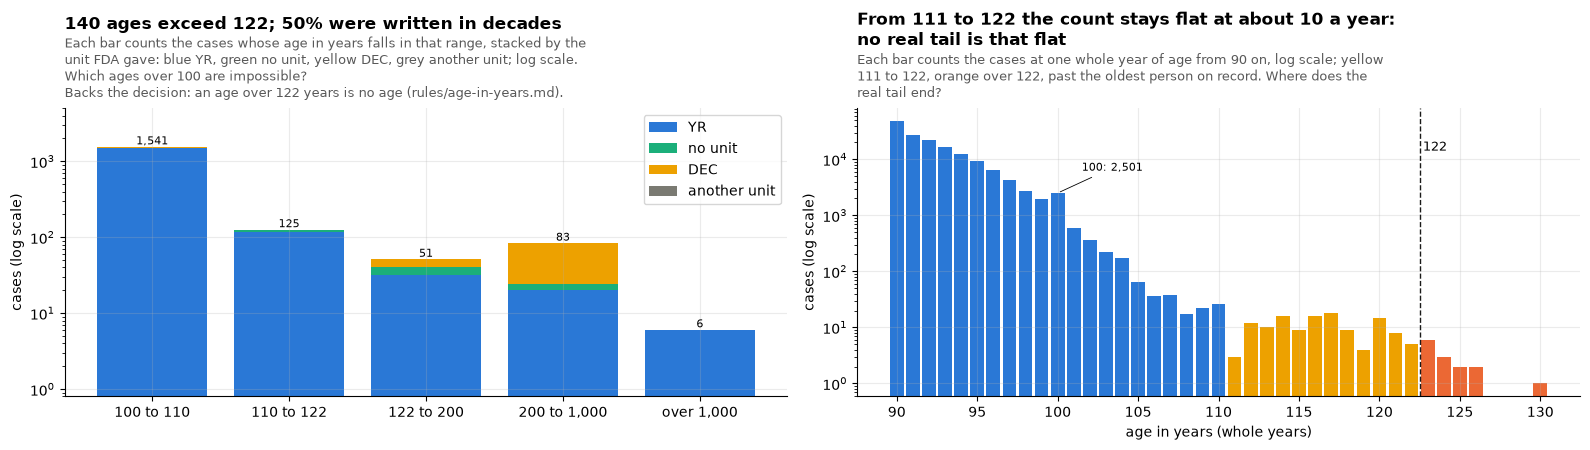

checked twice: cases older than 122 years, an age with no unit read as years = 140


140 cases are older than 122 (128 among the ages the release held before the decisions, the rest unitless). The commonest values: 50 DEC (10), 60 DEC (10), 20 DEC (9), 40 DEC (9), 70 DEC (9), 30 DEC (7). From 101 to 110 the count falls from 582 to 26; from 111 to 122 it runs between 3 and 18.


**What section 4 shows**, one item per chart:

- **Ages over 100, by range.** *Shows:* 140 ages exceed 122, 50% of them written in decades (`60 DEC` reads as 600 years, an age in years given the decade unit); the commonest others are `123 YR`, `124 YR`, `125 YR`, `126 YR`, `144 YR`. *Point:* none is a real age and there is no safe way to guess the right one. *So what:* an age over 122 years is no age, as DiAna does (140 cases).
- **The oldest ages, year by year.** *Shows:* the count falls smoothly to 110 (26 cases), then stays flat from 111 to 122 at about 10 a year; 100 stands out (2,501, against 1,956 at 99 and 582 at 101), a round number ages are drawn to. *Point:* most ages from 111 to 122 are errors too, but nothing marks which. *So what:* the cap follows the human record, as DiAna's does; the methods page says that the few ages from 111 to 122 are mostly errors.


In [8]:
hi = q(f"""SELECT CASE WHEN age_cod IS NULL THEN 'no unit' WHEN age_cod IN ('YR', 'DEC') THEN age_cod ELSE 'another unit' END unit,
                  CASE WHEN a <= 110 THEN '100 to 110' WHEN a <= 122 THEN '110 to 122' WHEN a <= 200 THEN '122 to 200'
                       WHEN a <= 1000 THEN '200 to 1,000' ELSE 'over 1,000' END b, count(*) cases
           FROM (SELECT age_cod, {AGE_ANY} a FROM case_latest_T) WHERE a > 100 GROUP BY ALL""")
yrs = (
    q(
        f"""SELECT floor(a) y, count(*) cases FROM (SELECT {AGE_ANY} a FROM case_latest_T) WHERE a >= 90 AND a < 131 GROUP BY 1 ORDER BY 1"""
    )
    .set_index("y")
    .cases
)
flat = yrs.loc[111:122]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.6))
p = (
    hi.pivot(index="b", columns="unit", values="cases")
    .reindex(["100 to 110", "110 to 122", "122 to 200", "200 to 1,000", "over 1,000"])
    .fillna(0)
)
bottom = np.zeros(len(p))
for u, c in [
    ("YR", SERIES[0]),
    ("no unit", SERIES[2]),
    ("DEC", SERIES[3]),
    ("another unit", SERIES[6]),
]:
    if u in p:
        a1.bar(p.index, p[u], bottom=bottom, color=c, label=u)
        bottom += p[u].values
for i, v in enumerate(bottom):
    a1.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=8)
a1.set_yscale("log")
a1.set_ylim(0.8, 5000)
a1.set_ylabel("cases (log scale)")
a1.legend()
past = p.loc[["122 to 200", "200 to 1,000", "over 1,000"]]
title(
    a1,
    f"{int(past.values.sum()):,} ages exceed 122; {pct(past.get('DEC', pd.Series(0)).sum(), past.values.sum()):.0f}% were written in decades",
    "Each bar counts the cases whose age in years falls in that range, stacked by the unit FDA gave: blue YR, green no unit, yellow DEC, grey another unit; log scale.",
    "Which ages over 100 are impossible?",
    backs("an age over 122 years is no age", "age"),
    width=80,
)
a2.bar(
    yrs.index,
    yrs.values,
    color=[SERIES[1] if v > AGE_CAP else SERIES[3] if v > 110 else SERIES[0] for v in yrs.index],
    width=0.85,
)
a2.set_yscale("log")
a2.axvline(AGE_CAP + 0.5, color="#1a1a19", lw=1, ls="--")
a2.text(AGE_CAP + 0.7, yrs.max() * 0.3, "122", fontsize=9)
a2.annotate(
    f"100: {yrs.get(100, 0):,}",
    (100, yrs.get(100, 1)),
    xytext=(101.5, yrs.get(100, 1) * 2.5),
    fontsize=8,
    arrowprops={"arrowstyle": "-", "lw": 0.6},
)
a2.set_xlabel("age in years (whole years)")
a2.set_ylabel("cases (log scale)")
title(
    a2,
    f"From 111 to 122 the count stays flat at about {flat.mean():.0f} a year: no real tail is that flat",
    "Each bar counts the cases at one whole year of age from 90 on, log scale; yellow 111 to 122, orange over 122, past the oldest person on record.",
    "Where does the real tail end?",
    width=80,
)
plt.tight_layout()
plt.show()
over = check(
    "cases older than 122 years, an age with no unit read as years",
    one(f"SELECT count(*) FROM case_latest_T WHERE {AGE_ANY} > {AGE_CAP}"),
    one(rf"""SELECT count(*) FROM {SECOND} WHERE regexp_full_match(trim(age), '[0-9]*\.?[0-9]*') AND regexp_matches(age, '[0-9]') AND (
                       (coalesce(age_cod, 'YR') = 'YR' AND trim(age)::DOUBLE > 122) OR (age_cod = 'DEC' AND trim(age)::DOUBLE > 12.2) OR (age_cod = 'MON' AND trim(age)::DOUBLE > 1464)
                       OR (age_cod = 'WK' AND trim(age)::DOUBLE > 122 * 365.25 / 7) OR (age_cod = 'DY' AND trim(age)::DOUBLE > 122 * 365.25) OR (age_cod = 'HR' AND trim(age)::DOUBLE > 122 * 8766)
                       OR (age_cod = 'MIN' AND trim(age)::DOUBLE > 122 * 525960) OR (age_cod = 'SEC' AND trim(age)::DOUBLE > 122 * 31557600))"""),
)
held_over = one(f"SELECT count(*) FROM case_latest_T WHERE {OLD_AGE} > {AGE_CAP}")
examples = q(
    f"SELECT age || ' ' || coalesce(age_cod, '(no unit)') v, count(*) n FROM case_latest_T WHERE {AGE_ANY} > {AGE_CAP} GROUP BY 1 ORDER BY 2 DESC, 1 LIMIT 6"
)
not_dec = q(
    f"SELECT age || ' ' || coalesce(age_cod, '(no unit)') v, count(*) n FROM case_latest_T WHERE {AGE_ANY} > {AGE_CAP} AND coalesce(age_cod, '') <> 'DEC' GROUP BY 1 ORDER BY 2 DESC, 1 LIMIT 5"
)
print(
    f"{over:,} cases are older than 122 ({held_over:,} among the ages the release held before the decisions, the rest unitless). The commonest values: "
    + ", ".join(f"{r.v} ({r.n})" for r in examples.itertuples())
    + f". From 101 to 110 the count falls from {yrs.get(101, 0):,} to {yrs.get(110, 0):,}; from 111 to 122 it runs between {flat.min():,} and {flat.max():,}."
)
say(f"""**What section 4 shows**, one item per chart:

- **Ages over 100, by range.** *Shows:* {int(past.values.sum()):,} ages exceed 122, {pct(past.get("DEC", pd.Series(0)).sum(), past.values.sum()):.0f}% of them written in decades (`60 DEC` reads as 600 years, an age in years given the decade unit); the commonest others are {", ".join(f"`{v}`" for v in not_dec.v)}. *Point:* none is a real age and there is no safe way to guess the right one. *So what:* an age over 122 years is no age, as DiAna does ({over:,} cases).
- **The oldest ages, year by year.** *Shows:* the count falls smoothly to 110 ({yrs.get(110, 0):,} cases), then stays flat from 111 to 122 at about {flat.mean():.0f} a year; 100 stands out ({yrs.get(100, 0):,}, against {yrs.get(99, 0):,} at 99 and {yrs.get(101, 0):,} at 101), a round number ages are drawn to. *Point:* most ages from 111 to 122 are errors too, but nothing marks which. *So what:* the cap follows the human record, as DiAna's does; the methods page says that the few ages from 111 to 122 are mostly errors.
""")

## 5. Age bands

### Which bands are in use, and can one set serve both apps?

Before the decision our code had two sets: the explorer's seven bands (also the statistics' strata) and the signal app's five. DiAna has six. ICH E11 defines only children's bands, and FDA's `age_grp` names groups without edges. The chart lays them on one axis with the set both apps now share. (*ICH E11 ends adolescence at 16 to 18 depending on the region; 17 is the common reading.)

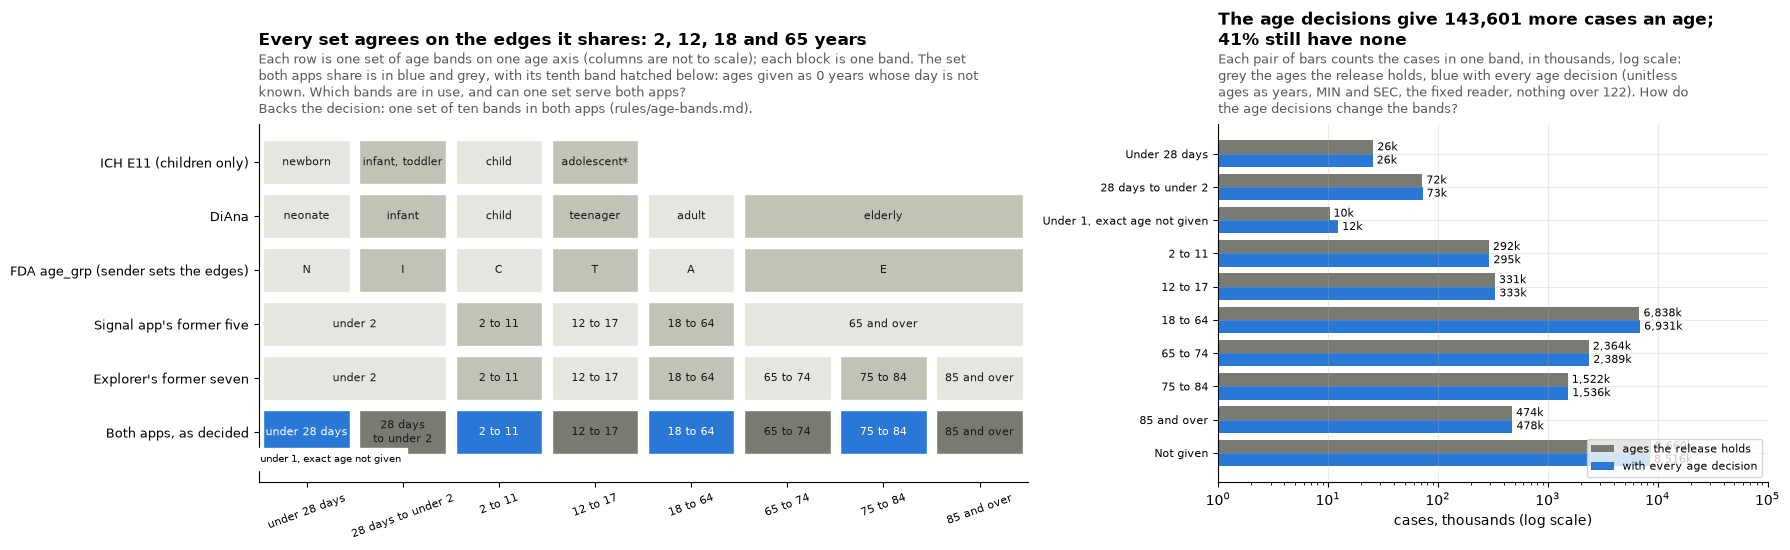

checked twice: cases with no age in years as decided = 8,516,248
As decided, 8,516,248 cases (41.4%) have no age; 143,601 more have one than the release held before the decisions. 4,402,887 cases are 65 or over, split three ways.


In [9]:
COLS = [
    "under 28 days",
    "28 days to under 2",
    "2 to 11",
    "12 to 17",
    "18 to 64",
    "65 to 74",
    "75 to 84",
    "85 and over",
]
SCHEMES = [
    (
        "ICH E11 (children only)",
        [("newborn", 0, 0), ("infant, toddler", 1, 1), ("child", 2, 2), ("adolescent*", 3, 3)],
    ),
    (
        "DiAna",
        [
            ("neonate", 0, 0),
            ("infant", 1, 1),
            ("child", 2, 2),
            ("teenager", 3, 3),
            ("adult", 4, 4),
            ("elderly", 5, 7),
        ],
    ),
    (
        "FDA age_grp (sender sets the edges)",
        [("N", 0, 0), ("I", 1, 1), ("C", 2, 2), ("T", 3, 3), ("A", 4, 4), ("E", 5, 7)],
    ),
    (
        "Signal app's former five",
        [
            ("under 2", 0, 1),
            ("2 to 11", 2, 2),
            ("12 to 17", 3, 3),
            ("18 to 64", 4, 4),
            ("65 and over", 5, 7),
        ],
    ),
    (
        "Explorer's former seven",
        [
            ("under 2", 0, 1),
            ("2 to 11", 2, 2),
            ("12 to 17", 3, 3),
            ("18 to 64", 4, 4),
            ("65 to 74", 5, 5),
            ("75 to 84", 6, 6),
            ("85 and over", 7, 7),
        ],
    ),
    (
        "Both apps, as decided",
        [
            ("under 28 days", 0, 0),
            ("28 days to under 2", 1, 1),
            ("2 to 11", 2, 2),
            ("12 to 17", 3, 3),
            ("18 to 64", 4, 4),
            ("65 to 74", 5, 5),
            ("75 to 84", 6, 6),
            ("85 and over", 7, 7),
        ],
    ),
]
bands = q(f"""SELECT {band(OLD_AGE, ZERO_HELD)} band, 'ages the release holds' k, count(*) cases FROM case_latest_T GROUP BY ALL
              UNION ALL
              SELECT {band(AGE_RULED, ZERO_YEARS)} band, 'every age decision' k, count(*) cases FROM case_latest_T GROUP BY ALL""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 5.6), gridspec_kw={"width_ratios": [1.4, 1]})
for i, (name, spans) in enumerate(SCHEMES):
    ours = name.startswith("Both")
    for j, (label, s, e) in enumerate(spans):
        a1.barh(
            i,
            e - s + 0.9,
            left=s - 0.45,
            color=SERIES[j % 2 * 6] if ours else (SERIES[7] if j % 2 else "#e6e5df"),
            edgecolor="white",
        )
        a1.text(
            (s + e) / 2,
            i,
            label.replace("days to", "days\nto") if ours else label,
            ha="center",
            va="center",
            fontsize=8,
            color="white" if ours and j % 2 == 0 else "#1a1a19",
        )
row = len(SCHEMES) - 1
a1.barh(row + 0.5, 1.4, left=-0.45, height=0.26, color="white", edgecolor=SERIES[0], hatch="///")
a1.text(
    0.25,
    row + 0.5,
    "under 1, exact age not given",
    ha="center",
    va="center",
    fontsize=7,
    backgroundcolor="white",
)
a1.set_yticks(range(len(SCHEMES)))
a1.set_yticklabels([n for n, _ in SCHEMES], fontsize=9)
a1.invert_yaxis()
a1.grid(False)
a1.set_xticks(range(len(COLS)))
a1.set_xticklabels(COLS, rotation=20, fontsize=8)
a1.set_xlim(-0.5, len(COLS) - 0.5)
title(
    a1,
    "Every set agrees on the edges it shares: 2, 12, 18 and 65 years",
    "Each row is one set of age bands on one age axis (columns are not to scale); each block is one band. The set both apps share is in blue and grey, "
    "with its tenth band hatched below: ages given as 0 years whose day is not known.",
    "Which bands are in use, and can one set serve both apps?",
    backs("one set of ten bands in both apps", "bands"),
    width=110,
)
p = bands.pivot(index="band", columns="k", values="cases").reindex(BANDS).fillna(0)
yy = np.arange(len(p))
w = 0.4
label_bars(
    a2,
    drawn(
        a2.barh(
            yy - w / 2,
            p["ages the release holds"] / 1e3,
            w,
            color=SERIES[6],
            label="ages the release holds",
        )
    ),
    "{:,.0f}k",
    horizontal=True,
)
label_bars(
    a2,
    drawn(
        a2.barh(
            yy + w / 2,
            p["every age decision"] / 1e3,
            w,
            color=SERIES[0],
            label="with every age decision",
        )
    ),
    "{:,.0f}k",
    horizontal=True,
)
a2.set_yticks(yy)
a2.set_yticklabels(p.index, fontsize=8)
a2.invert_yaxis()
a2.set_xscale("log")
a2.set_xlim(1, 1e5)
a2.set_xlabel("cases, thousands (log scale)")
a2.legend(fontsize=8, loc="lower right")
gained = int(
    p.loc["Not given", "ages the release holds"] - p.loc["Not given", "every age decision"]
)
title(
    a2,
    f"The age decisions give {gained:,} more cases an age; {pct(p.loc['Not given', 'every age decision'], N_CASES):.0f}% still have none",
    "Each pair of bars counts the cases in one band, in thousands, log scale: grey the ages the release holds, blue with every age decision (unitless ages as years, MIN and SEC, the fixed reader, nothing over 122).",
    "How do the age decisions change the bands?",
    width=73,
)
plt.tight_layout()
plt.show()
ng = check(
    "cases with no age in years as decided",
    one(f"SELECT count(*) FROM case_latest_T WHERE {AGE_RULED} IS NULL"),
    one(rf"""SELECT count(*) FROM {SECOND} WHERE NOT (coalesce(age_cod, 'YR') IN ('YR', 'DEC', 'MON', 'WK', 'DY', 'HR', 'MIN', 'SEC')
                                                    AND coalesce(regexp_full_match(trim(age), '[0-9]*\.?[0-9]*') AND regexp_matches(age, '[0-9]'), false))
                                             OR {AGE_ANY} > {AGE_CAP}"""),
)
old = p.loc[["65 to 74", "75 to 84", "85 and over"], "every age decision"].sum()
band_gain = (p["every age decision"] - p["ages the release holds"]).drop("Not given")
adult_gain = pct(
    band_gain[["18 to 64", "65 to 74", "75 to 84", "85 and over"]].sum(), band_gain.sum()
)
print(
    f"As decided, {ng:,} cases ({pct(ng, N_CASES):.1f}%) have no age; {gained:,} more have one than the release held before the decisions. "
    f"{int(old):,} cases are 65 or over, split three ways."
)

### Where do babies given as 0 years go?

An age of 0 years says the baby was under 1 but not how many days old. Counted in days, as DiAna counts, 0 years becomes 0 days, a newborn. The sender's own group can place some of them: `N` (neonate) under 28 days, `I` (infant) in 28 days to under 2. The rest go to a band of their own.

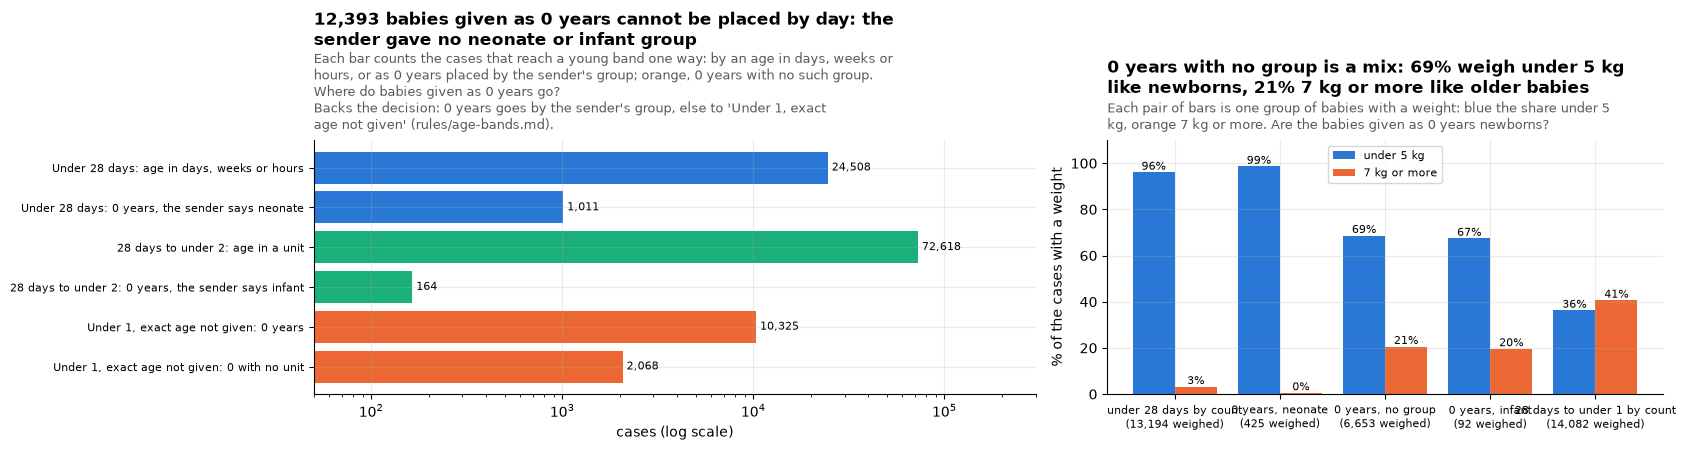

checked twice: babies given as 0 years with no neonate or infant group = 12,393
Babies given as 0 years: 1,011 with the sender's neonate group, 164 with infant, 10,325 in years and 2,068 with no unit and neither group.


**What section 5 shows**, one item per chart:

- **The sets of bands on one axis.** *Shows:* every set agrees on the edges it shares, 2, 12, 18 and 65 years; they differ only in how finely they cut the two ends. *Point:* one set can serve both apps without moving an edge either already uses. *So what:* both apps use the same ten bands: Under 28 days, 28 days to under 2, Under 1 with the exact age not given, 2 to 11, 12 to 17, 18 to 64, 65 to 74, 75 to 84, 85 and over, Not given. The signal app's "65 and over" becomes three bands, 4,402,887 cases; ticking the three young bands together gives under 2.
- **Cases per band.** *Shows:* the age decisions give 143,601 more cases an age; 41% of cases still have none. *Point:* 94% of the ages gained are 18 or over; the young bands barely move. *So what:* "Not given" stays the largest band and is shown, not hidden.
- **Where babies given as 0 years go.** *Shows:* 1,011 go to under 28 days by the sender's neonate group and 164 to 28 days to under 2 by the infant group; 12,393 have neither, against 24,508 under 28 days by a day, week or hour count. *Point:* 0 years cannot be placed by day without the sender's group. *So what:* they go to "Under 1, exact age not given", in both apps: being right is worth more than matching DiAna, which would count them as newborns.
- **Whether those babies are newborns.** *Shows:* 69% of the 0-year babies with no group weigh under 5 kg and 21% 7 kg or more; babies under 28 days by count weigh under 5 kg 96% of the time, babies from 28 days to under 1 36%. *Point:* most look newborn, a fifth do not, and nothing says which. *So what:* a band of their own is the honest place.


In [10]:
yb = (
    q(f"""SELECT CASE WHEN {ZERO_YEARS} AND age_grp = 'N' THEN 'Under 28 days: 0 years, the sender says neonate'
                       WHEN {ZERO_YEARS} AND age_grp = 'I' THEN '28 days to under 2: 0 years, the sender says infant'
                       WHEN {ZERO_YEARS} AND age_cod IS NULL THEN 'Under 1, exact age not given: 0 with no unit'
                       WHEN {ZERO_YEARS} THEN 'Under 1, exact age not given: 0 years'
                       WHEN {AGE_RULED} < 28 / 365.25 THEN 'Under 28 days: age in days, weeks or hours'
                       WHEN {AGE_RULED} < 2 THEN '28 days to under 2: age in a unit' END k, count(*) cases,
                  count(wt_kg_T) with_weight, 100 * avg((wt_kg_T < 5)::INT) FILTER (WHERE wt_kg_T IS NOT NULL) light,
                  100 * avg((wt_kg_T >= 7)::INT) FILTER (WHERE wt_kg_T IS NOT NULL) heavy
           FROM case_latest_T GROUP BY 1""")
    .dropna(subset=["k"])
    .set_index("k")
)
KORDER = [
    "Under 28 days: age in days, weeks or hours",
    "Under 28 days: 0 years, the sender says neonate",
    "28 days to under 2: age in a unit",
    "28 days to under 2: 0 years, the sender says infant",
    "Under 1, exact age not given: 0 years",
    "Under 1, exact age not given: 0 with no unit",
]
yb = yb.reindex(KORDER).fillna(0)
wb = (
    q(f"""SELECT CASE WHEN {ZERO_YEARS} AND age_grp = 'N' THEN '0 years, neonate'
                       WHEN {ZERO_YEARS} AND age_grp = 'I' THEN '0 years, infant'
                       WHEN {ZERO_YEARS} THEN '0 years, no group'
                       WHEN {AGE_RULED} < 28 / 365.25 THEN 'under 28 days by count'
                       WHEN {AGE_RULED} < 1 THEN '28 days to under 1 by count' END k,
                  100 * avg((wt_kg_T < 5)::INT) light, 100 * avg((wt_kg_T >= 7)::INT) heavy, count(*) n
           FROM case_latest_T WHERE wt_kg_T IS NOT NULL GROUP BY 1""")
    .dropna(subset=["k"])
    .set_index("k")
)
wb = wb.reindex(
    [
        "under 28 days by count",
        "0 years, neonate",
        "0 years, no group",
        "0 years, infant",
        "28 days to under 1 by count",
    ]
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
colors = [SERIES[0], SERIES[0], SERIES[2], SERIES[2], SERIES[1], SERIES[1]]
label_bars(a1, drawn(a1.barh(yb.index[::-1], yb.cases[::-1], color=colors[::-1])), horizontal=True)
a1.set_xscale("log")
a1.set_xlim(50, 3e5)
a1.set_xlabel("cases (log scale)")
a1.tick_params(axis="y", labelsize=8)
none = int(yb.loc[KORDER[4:], "cases"].sum())
title(
    a1,
    f"{none:,} babies given as 0 years cannot be placed by day: the sender gave no neonate or infant group",
    "Each bar counts the cases that reach a young band one way: by an age in days, weeks or hours, or as 0 years placed by the sender's group; "
    "orange, 0 years with no such group.",
    "Where do babies given as 0 years go?",
    backs("0 years goes by the sender's group, else to 'Under 1, exact age not given'", "bands"),
    width=88,
)
x = np.arange(len(wb))
a2.bar(x - 0.2, wb.light, 0.4, color=SERIES[0], label="under 5 kg")
a2.bar(x + 0.2, wb.heavy, 0.4, color=SERIES[1], label="7 kg or more")
for i, r in enumerate(wb.itertuples()):
    a2.text(i - 0.2, r.light, f"{r.light:.0f}%", ha="center", va="bottom", fontsize=8)
    a2.text(i + 0.2, r.heavy, f"{r.heavy:.0f}%", ha="center", va="bottom", fontsize=8)
a2.set_xticks(x)
a2.set_xticklabels(
    [f"{k}\n({int(n):,} weighed)" for k, n in zip(wb.index, wb.n, strict=True)], fontsize=8
)
a2.set_ylim(0, 110)
a2.set_ylabel("% of the cases with a weight")
a2.legend(fontsize=8, loc="upper center")
nog = wb.loc["0 years, no group"]
title(
    a2,
    f"0 years with no group is a mix: {nog.light:.0f}% weigh under 5 kg like newborns, {nog.heavy:.0f}% 7 kg or more like older babies",
    "Each pair of bars is one group of babies with a weight: blue the share under 5 kg, orange 7 kg or more.",
    "Are the babies given as 0 years newborns?",
    width=78,
)
plt.tight_layout()
plt.show()
none2 = check(
    "babies given as 0 years with no neonate or infant group",
    none,
    one(rf"""SELECT count(*) FROM {SECOND} WHERE regexp_full_match(trim(age), '0*\.?0*') AND regexp_matches(age, '0')
             AND coalesce(age_cod, 'YR') IN ('YR', 'DEC') AND coalesce(age_grp, '') NOT IN ('N', 'I')"""),
)
print(
    f"Babies given as 0 years: {int(yb.loc[KORDER[1], 'cases']):,} with the sender's neonate group, {int(yb.loc[KORDER[3], 'cases']):,} with infant, "
    f"{int(yb.loc[KORDER[4], 'cases']):,} in years and {int(yb.loc[KORDER[5], 'cases']):,} with no unit and neither group."
)
say(f"""**What section 5 shows**, one item per chart:

- **The sets of bands on one axis.** *Shows:* every set agrees on the edges it shares, 2, 12, 18 and 65 years; they differ only in how finely they cut the two ends. *Point:* one set can serve both apps without moving an edge either already uses. *So what:* both apps use the same ten bands: Under 28 days, 28 days to under 2, Under 1 with the exact age not given, 2 to 11, 12 to 17, 18 to 64, 65 to 74, 75 to 84, 85 and over, Not given. The signal app's "65 and over" becomes three bands, {int(old):,} cases; ticking the three young bands together gives under 2.
- **Cases per band.** *Shows:* the age decisions give {gained:,} more cases an age; {pct(ng, N_CASES):.0f}% of cases still have none. *Point:* {adult_gain:.0f}% of the ages gained are 18 or over; the young bands barely move. *So what:* "Not given" stays the largest band and is shown, not hidden.
- **Where babies given as 0 years go.** *Shows:* {int(yb.loc[KORDER[1], "cases"]):,} go to under 28 days by the sender's neonate group and {int(yb.loc[KORDER[3], "cases"]):,} to 28 days to under 2 by the infant group; {none:,} have neither, against {int(yb.loc[KORDER[0], "cases"]):,} under 28 days by a day, week or hour count. *Point:* 0 years cannot be placed by day without the sender's group. *So what:* they go to "Under 1, exact age not given", in both apps: being right is worth more than matching DiAna, which would count them as newborns.
- **Whether those babies are newborns.** *Shows:* {nog.light:.0f}% of the 0-year babies with no group weigh under 5 kg and {nog.heavy:.0f}% 7 kg or more; babies under 28 days by count weigh under 5 kg {wb.loc["under 28 days by count", "light"]:.0f}% of the time, babies from 28 days to under 1 {wb.loc["28 days to under 1 by count", "light"]:.0f}%. *Point:* most look newborn, a fifth do not, and nothing says which. *So what:* a band of their own is the honest place.
""")

## 6. Weight

### Which units appear, and which weights need a decision?

FDA gives `wt` and `wt_cod`: `KG`, `LBS` and `GMS` (and `KGS` on a few cases). The release's `wt_kg_T` converts those and gives nothing for anything else. The right chart puts each case whose weight is not plainly usable into one group, the first that fits from the top.

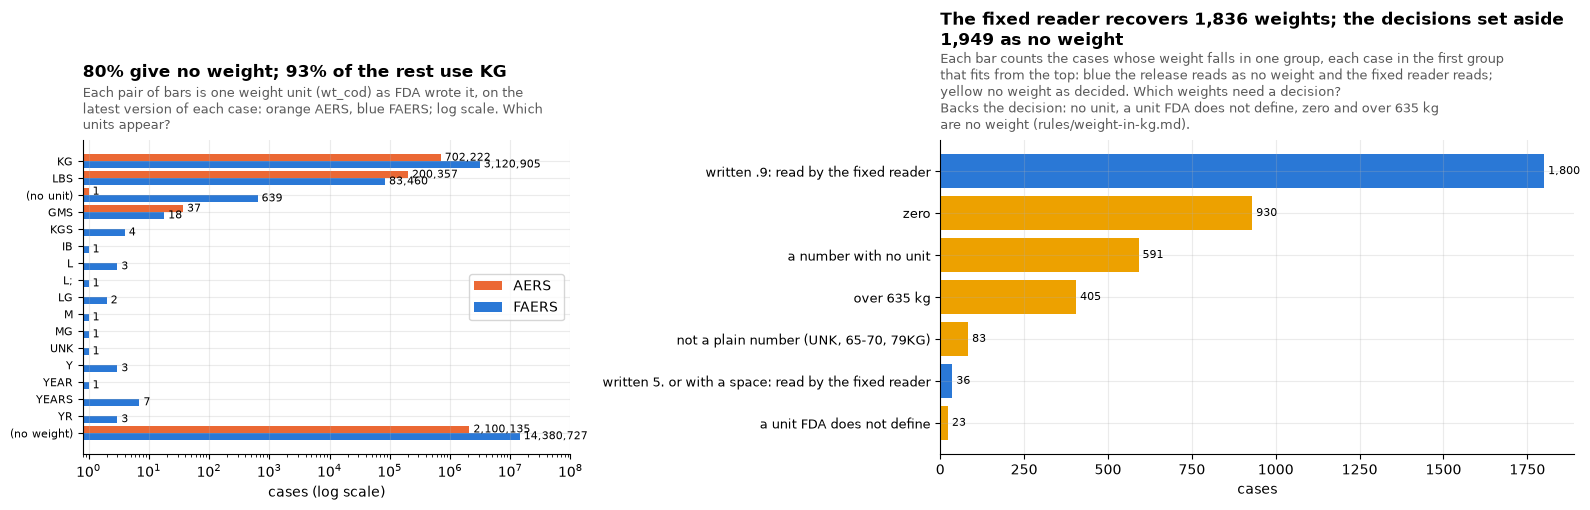

checked twice: cases whose weight is written with a leading point (.9) in a known unit = 1,800


checked twice: cases whose weight is zero in a known unit = 930


checked twice: cases with a weight number but no unit = 591
4,103,799 cases have a usable weight. The fixed reader reads 1,836 more: 1,800 written with a leading point (.9 for 0.9) and 36 written 5. or with a space. Units FDA does not define: YEARS 7, L 3, Y 3, YR 3, LG 2, IB 1.


In [11]:
NUMW = r"regexp_full_match(wt, '[0-9]+(\.[0-9]+)?')"
wu = q(
    """SELECT era_T, CASE WHEN wt IS NULL THEN '(no weight)' ELSE coalesce(wt_cod, '(no unit)') END unit, count(*) cases FROM case_latest_T GROUP BY ALL"""
)
KIND = f"""CASE WHEN wt IS NULL THEN 'no weight'
                WHEN {number("wt")} IS NULL THEN 'not a plain number (UNK, 65-70, 79KG)'
                WHEN wt_cod IS NULL THEN 'a number with no unit'
                WHEN wt_cod NOT IN ('KG', 'KGS', 'LBS', 'GMS') THEN 'a unit FDA does not define'
                WHEN NOT {NUMW} AND starts_with(trim(wt), '.') THEN 'written .9: read by the fixed reader'
                WHEN NOT {NUMW} THEN 'written 5. or with a space: read by the fixed reader'
                WHEN {number("wt")} = 0 THEN 'zero'
                WHEN {WT_ANY} > {WT_CAP} THEN 'over 635 kg'
                ELSE 'usable' END"""
wk = q(f"SELECT {KIND} kind, count(*) cases FROM case_latest_T GROUP BY 1").set_index("kind").cases
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
order = ["KG", "LBS", "(no unit)", "GMS", "KGS"]
units = (
    [o for o in order if o in set(wu.unit)]
    + sorted(set(wu.unit) - set(order) - {"(no weight)"})
    + ["(no weight)"]
)
piv = wu.pivot(index="unit", columns="era_T", values="cases").reindex(units).fillna(0)
y = np.arange(len(piv))
h = 0.4
for i, era in enumerate(["legacy", "faers"]):
    if era in piv:
        label_bars(
            a1,
            drawn(a1.barh(y + (i - 0.5) * h, piv[era], h, color=ERA[era], label=ERA_NAME[era])),
            horizontal=True,
        )
a1.set_yticks(y)
a1.set_yticklabels(piv.index, fontsize=8)
a1.invert_yaxis()
a1.set_xscale("log")
a1.set_xlim(0.8, 1e8)
a1.set_xlabel("cases (log scale)")
a1.legend(loc="center right")
nw = piv.loc["(no weight)"].sum()
title(
    a1,
    f"{pct(nw, piv.values.sum()):.0f}% give no weight; {pct(piv.loc['KG'].sum(), piv.values.sum() - nw):.0f}% of the rest use KG",
    "Each pair of bars is one weight unit (wt_cod) as FDA wrote it, on the latest version of each case: orange AERS, blue FAERS; log scale.",
    "Which units appear?",
    width=70,
)
probs = wk.drop(["no weight", "usable"], errors="ignore").sort_values()
label_bars(
    a2,
    drawn(
        a2.barh(
            probs.index,
            probs.values,
            color=[SERIES[0] if "reader" in k else SERIES[3] for k in probs.index],
        )
    ),
    horizontal=True,
)
a2.set_xlabel("cases")
a2.tick_params(axis="y", labelsize=9)
fixed = int(probs[[k for k in probs.index if "reader" in k]].sum())
aside = int(
    probs[[k for k in probs.index if "reader" not in k and "not a plain number" not in k]].sum()
)
title(
    a2,
    f"The fixed reader recovers {fixed:,} weights; the decisions set aside {aside:,} as no weight",
    "Each bar counts the cases whose weight falls in one group, each case in the first group that fits from the top: blue the release reads as no weight and the fixed reader reads; "
    "yellow no weight as decided.",
    "Which weights need a decision?",
    backs("no unit, a unit FDA does not define, zero and over 635 kg are no weight", "weight"),
    width=90,
)
plt.tight_layout()
plt.show()
dot_n = check(
    "cases whose weight is written with a leading point (.9) in a known unit",
    int(wk.get("written .9: read by the fixed reader", 0)),
    one(
        f"SELECT count(*) FROM {SECOND} WHERE wt_cod IN ('KG', 'KGS', 'LBS', 'GMS') AND starts_with(trim(wt), '.') AND TRY_CAST(wt AS DOUBLE) IS NOT NULL"
    ),
)
zero_n = check(
    "cases whose weight is zero in a known unit",
    int(wk.get("zero", 0)),
    one(
        f"SELECT count(*) FROM {SECOND} WHERE wt_cod IN ('KG', 'KGS', 'LBS', 'GMS') AND {NUMW} AND wt::DOUBLE = 0"
    ),
)
nounit_n = check(
    "cases with a weight number but no unit",
    int(wk.get("a number with no unit", 0)),
    one(f"SELECT count(*) FROM {SECOND} WHERE wt_cod IS NULL AND {number('wt')} IS NOT NULL"),
)
odd_units = q(
    "SELECT wt_cod, count(*) cases FROM case_latest_T WHERE wt_cod NOT IN ('KG', 'KGS', 'LBS', 'GMS') GROUP BY 1 ORDER BY 2 DESC, 1 LIMIT 6"
)
print(
    f"{wk.get('usable', 0):,} cases have a usable weight. The fixed reader reads {fixed:,} more: {dot_n:,} written with a leading point (.9 for 0.9) and "
    f"{fixed - dot_n:,} written 5. or with a space. Units FDA does not define: "
    + ", ".join(f"{r.wt_cod} {r.cases}" for r in odd_units.itertuples())
    + "."
)

### Where does the 635 kg cap fall, and are unitless weights in kilograms?

The heaviest person on record weighed about 635 kg; DiAna drops anything heavier. DiAna also reads a weight with no unit as kilograms.

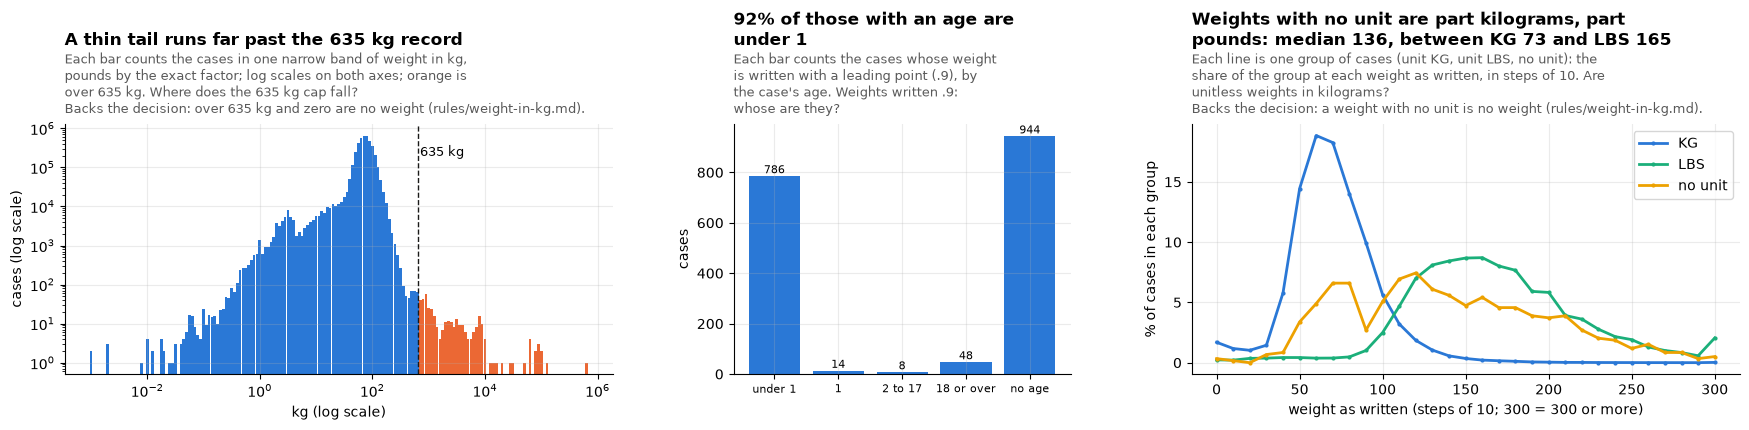

checked twice: cases over 635 kg, pounds by the exact factor = 405


405 cases weigh over 635 kg, the heaviest 660000 KG (aged 45), 268000 LBS (aged 63), 104396 KG (aged 53). As decided, 4,105,635 cases have a weight: 1,836 more than the release held before the decisions, 1,335 fewer. Pounds by the exact factor (0.45359237, not 0.45359) move a weight by at most 3.3 g. Median weight as written: KG 73, LBS 165, no unit 136 (591 cases).


**What section 6 shows**, one item per chart:

- **Which units appear.** *Shows:* 80% of cases give no weight; 93% of the rest use KG, then LBS, then a few with no unit or grams. *Point:* weights are scarce but plainly written. *So what:* KG, LBS and GMS convert, pounds by the exact factor 0.45359237.
- **Which weights need a decision.** *Shows:* the fixed reader recovers 1,836 weights the release reads as none, 1,800 of them written .9; the decisions set aside 1,949: zero 930, over 635 kg 405, no unit 591, a unit FDA does not define 23. *Point:* the reader is a bug, not a choice; the rest cannot be read safely. *So what:* the reader is fixed in both builds; the others are no weight.
- **The 635 kg cap.** *Shows:* a thin tail of 405 cases runs far past 635 kg, up to 660000 KG. *Point:* stray digits and misplaced points, nothing real. *So what:* over 635 kg is no weight, as DiAna does, and so is zero.
- **Weights written .9.** *Shows:* 92% of those with an age are under 1. *Point:* the bug hid newborns' weights, the ones paediatric safety needs. *So what:* the fixed reader gives them back.
- **Weights with no unit.** *Shows:* their median (136) sits between kilograms (73) and pounds (165), with one hump where kilograms fall and one where pounds fall. *Point:* read as kilograms, as DiAna does, the pounds among them would come out more than twice too heavy. *So what:* a weight with no unit is no weight (591 cases).


In [12]:
W = number("wt")
lg = q(
    f"SELECT round(log10(kg) * 20) / 20 b, count(*) cases FROM (SELECT {WT_ANY} kg FROM case_latest_T) WHERE kg > 0 GROUP BY 1 ORDER BY 1"
)
dot = (
    q(f"""SELECT CASE WHEN a IS NULL THEN 'no age' WHEN a < 1 THEN 'under 1' WHEN a < 2 THEN '1' WHEN a < 18 THEN '2 to 17' ELSE '18 or over' END a, count(*) cases
          FROM (SELECT {AGE_RULED} a FROM case_latest_T WHERE starts_with(trim(wt), '.') AND wt_cod IN ('KG', 'KGS', 'LBS', 'GMS')) GROUP BY 1""")
    .set_index("a")
    .cases.reindex(["under 1", "1", "2 to 17", "18 or over", "no age"])
    .fillna(0)
)
cmp_ = q(f"""SELECT coalesce(wt_cod, 'no unit') u, least(floor({W} / 10) * 10, 300) b, count(*) cases FROM case_latest_T
             WHERE {W} > 0 AND (wt_cod IS NULL OR wt_cod IN ('KG', 'LBS')) GROUP BY ALL""")
fig, (a1, a2, a3) = plt.subplots(
    1, 3, figsize=(18, 4.4), gridspec_kw={"width_ratios": [1.3, 0.8, 1.3]}
)
a1.bar(
    10**lg.b,
    lg.cases,
    width=10**lg.b * 0.11,
    color=[SERIES[1] if v > WT_CAP else SERIES[0] for v in 10**lg.b],
)
a1.axvline(WT_CAP, color="#1a1a19", lw=1, ls="--")
a1.text(700, lg.cases.max() * 0.3, "635 kg", fontsize=9)
a1.set_xscale("log")
a1.set_yscale("log")
a1.set_xlabel("kg (log scale)")
a1.set_ylabel("cases (log scale)")
title(
    a1,
    "A thin tail runs far past the 635 kg record",
    "Each bar counts the cases in one narrow band of weight in kg, pounds by the exact factor; log scales on both axes; orange is over 635 kg.",
    "Where does the 635 kg cap fall?",
    backs("over 635 kg and zero are no weight", "weight"),
    width=66,
)
label_bars(a2, drawn(a2.bar(dot.index, dot.values, color=SERIES[0])))
a2.set_ylabel("cases")
a2.tick_params(axis="x", labelsize=8)
title(
    a2,
    f"{pct(dot['under 1'], dot.drop('no age').sum()):.0f}% of those with an age are under 1",
    "Each bar counts the cases whose weight is written with a leading point (.9), by the case's age.",
    "Weights written .9: whose are they?",
    width=40,
)
c = cmp_.pivot(index="b", columns="u", values="cases").fillna(0)
c = 100 * c / c.sum()
for u, col in [("KG", SERIES[0]), ("LBS", SERIES[2]), ("no unit", SERIES[3])]:
    if u in c:
        a3.plot(c.index, c[u], color=col, label=u, marker="o", ms=2)
a3.set_xlabel("weight as written (steps of 10; 300 = 300 or more)")
a3.set_ylabel("% of cases in each group")
a3.legend()
med = q(
    f"SELECT coalesce(wt_cod, 'no unit') u, median({W}) m, count(*) cases FROM case_latest_T WHERE {W} > 0 AND (wt_cod IS NULL OR wt_cod IN ('KG', 'LBS')) GROUP BY 1"
).set_index("u")
title(
    a3,
    f"Weights with no unit are part kilograms, part pounds: median {med.m['no unit']:.0f}, between KG {med.m['KG']:.0f} and LBS {med.m['LBS']:.0f}",
    "Each line is one group of cases (unit KG, unit LBS, no unit): the share of the group at each weight as written, in steps of 10.",
    "Are unitless weights in kilograms?",
    backs("a weight with no unit is no weight", "weight"),
    width=66,
)
plt.tight_layout()
plt.show()
over = check(
    "cases over 635 kg, pounds by the exact factor",
    one(f"SELECT count(*) FROM case_latest_T WHERE {WT_ANY} > {WT_CAP}"),
    one(f"""SELECT count(*) FROM {SECOND} WHERE TRY_CAST(trim(wt) AS DOUBLE) IS NOT NULL AND NOT starts_with(trim(wt), '-') AND ((wt_cod IN ('KG', 'KGS') AND trim(wt)::DOUBLE > 635)
                                                           OR (wt_cod = 'LBS' AND trim(wt)::DOUBLE > 635 / 0.45359237) OR (wt_cod = 'GMS' AND trim(wt)::DOUBLE > 635000))"""),
)
ruled_w = q(f"""SELECT count(*) FILTER (WHERE r IS NOT NULL AND b IS NULL) gained, count(*) FILTER (WHERE r IS NULL AND b IS NOT NULL) lost,
                       max(abs(r - b)) FILTER (WHERE wt_cod = 'LBS') lbs_gap, count(r) n
                FROM (SELECT {WT_RULED} r, {OLD_WT} b, wt_cod FROM case_latest_T)""").iloc[0]
heaviest = q(
    f"SELECT wt || ' ' || wt_cod w, {AGE_RULED} a FROM case_latest_T WHERE {WT_ANY} > {WT_CAP} ORDER BY {WT_ANY} DESC LIMIT 3"
)
print(
    f"{over:,} cases weigh over 635 kg, the heaviest "
    + ", ".join(
        f"{r.w} (aged {r.a:.0f})" if pd.notna(r.a) else f"{r.w}" for r in heaviest.itertuples()
    )
    + f". As decided, {int(ruled_w.n):,} cases have a weight: {int(ruled_w.gained):,} more than the release held before the decisions, {int(ruled_w.lost):,} fewer. "
    f"Pounds by the exact factor (0.45359237, not 0.45359) move a weight by at most {1000 * ruled_w.lbs_gap:.1f} g. "
    f"Median weight as written: KG {med.m['KG']:.0f}, LBS {med.m['LBS']:.0f}, no unit {med.m['no unit']:.0f} ({int(med.cases['no unit']):,} cases)."
)
say(f"""**What section 6 shows**, one item per chart:

- **Which units appear.** *Shows:* {pct(nw, piv.values.sum()):.0f}% of cases give no weight; {pct(piv.loc["KG"].sum(), piv.values.sum() - nw):.0f}% of the rest use KG, then LBS, then a few with no unit or grams. *Point:* weights are scarce but plainly written. *So what:* KG, LBS and GMS convert, pounds by the exact factor 0.45359237.
- **Which weights need a decision.** *Shows:* the fixed reader recovers {fixed:,} weights the release reads as none, {dot_n:,} of them written .9; the decisions set aside {aside:,}: zero {zero_n:,}, over 635 kg {over:,}, no unit {nounit_n:,}, a unit FDA does not define {int(wk.get("a unit FDA does not define", 0)):,}. *Point:* the reader is a bug, not a choice; the rest cannot be read safely. *So what:* the reader is fixed in both builds; the others are no weight.
- **The 635 kg cap.** *Shows:* a thin tail of {over:,} cases runs far past 635 kg, up to {heaviest.w.iloc[0] if len(heaviest) else "none"}. *Point:* stray digits and misplaced points, nothing real. *So what:* over 635 kg is no weight, as DiAna does, and so is zero.
- **Weights written .9.** *Shows:* {pct(dot["under 1"], dot.drop("no age").sum()):.0f}% of those with an age are under 1. *Point:* the bug hid newborns' weights, the ones paediatric safety needs. *So what:* the fixed reader gives them back.
- **Weights with no unit.** *Shows:* their median ({med.m["no unit"]:.0f}) sits between kilograms ({med.m["KG"]:.0f}) and pounds ({med.m["LBS"]:.0f}), with one hump where kilograms fall and one where pounds fall. *Point:* read as kilograms, as DiAna does, the pounds among them would come out more than twice too heavy. *So what:* a weight with no unit is no weight ({nounit_n:,} cases).
""")

## 7. Country

### When is a country field not a country code?

The `legacy-country` rule turns AERS country names (`UNITED STATES`) into ISO codes (`US`). FAERS has two country fields: `occr_country`, where the event happened, and `reporter_country`. The release's `country_T` is the occurrence country, else the reporter's. These charts follow what in the two FAERS fields is not an ISO 3166-1 code, quarter by quarter.

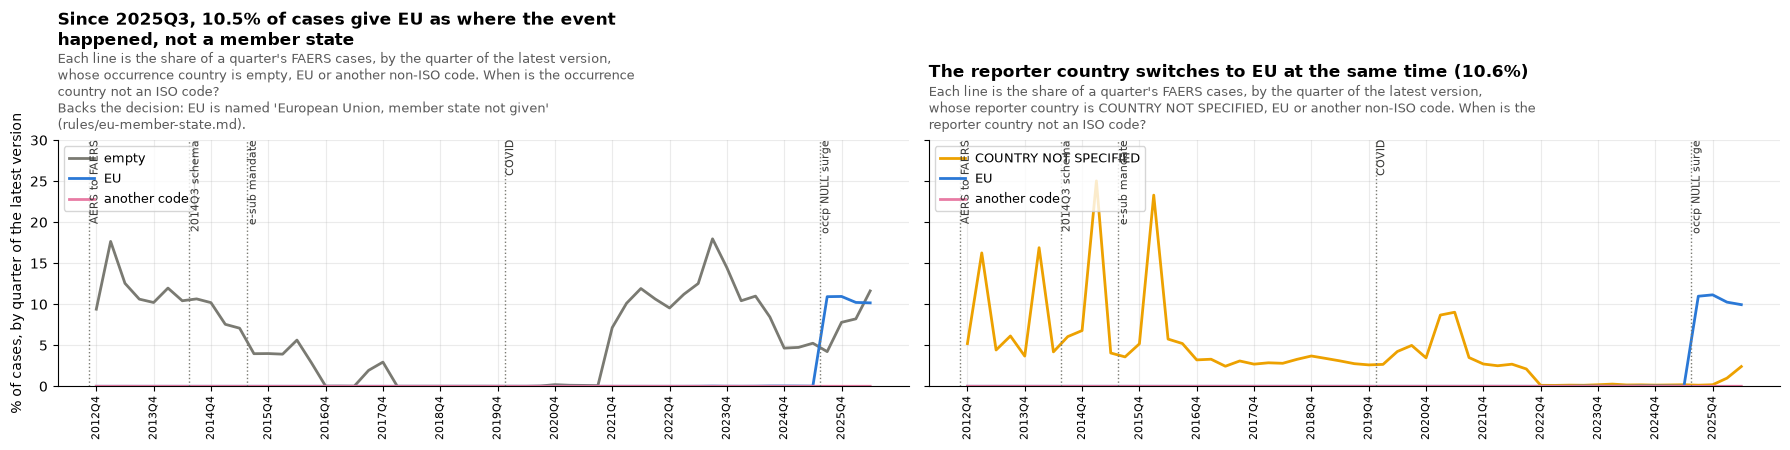

checked twice: FAERS cases whose occurrence country is EU = 161,964
checked twice: cases whose latest version is from 2025Q3 or later = 1,529,534
checked twice: of them, cases whose occurrence country is EU = 161,362
161,964 cases give EU as the occurrence country. Since 2025Q3, 161,362 of the 1,529,534 cases published (10.5%, counting those with no occurrence country), and 96% of these start their manufacturer case number with EU- where it used to start with the country. 16,013 of the EU cases were first received before 2025, so EU arrived with a follow-up.


In [13]:
def kind(col):
    return f"""CASE WHEN {col} IS NULL THEN 'empty' WHEN {col} = 'COUNTRY NOT SPECIFIED' THEN 'COUNTRY NOT SPECIFIED' WHEN {col} = 'EU' THEN 'EU'
                    WHEN {col} IN (SELECT code FROM iso2_df) THEN 'ISO code' ELSE 'another code' END"""


cq = q(f"""SELECT quarter_T, qnum_T, 'occurrence country' col, {kind("occr_country")} k, count(*) cases FROM case_latest_T WHERE era_T = 'faers' GROUP BY ALL
           UNION ALL
           SELECT quarter_T, qnum_T, 'reporter country', {kind("reporter_country")}, count(*) FROM case_latest_T WHERE era_T = 'faers' GROUP BY ALL""")
eu_recent = q("""SELECT count(*) total, count(*) FILTER (WHERE occr_country = 'EU') n, count(*) FILTER (WHERE reporter_country = 'EU') r,
                        count(*) FILTER (WHERE occr_country = 'EU' AND starts_with(mfr_num, 'EU-')) n_mfr_eu
                 FROM case_latest_T WHERE qnum_T >= 20253""").iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(18, 4.6), sharey=True)
CLAIM = {
    "occurrence country": f"Since 2025Q3, {pct(eu_recent.n, eu_recent.total):.1f}% of cases give EU as where the event happened, not a member state",
    "reporter country": f"The reporter country switches to EU at the same time ({pct(eu_recent.r, eu_recent.total):.1f}%)",
}
SHOWN = {
    "occurrence country": "empty, EU or another non-ISO code",
    "reporter country": "COUNTRY NOT SPECIFIED, EU or another non-ISO code",
}
for ax, col in zip(axes, ["occurrence country", "reporter country"], strict=True):
    d = (
        cq[cq.col == col]
        .pivot_table(index=["qnum_T", "quarter_T"], columns="k", values="cases", aggfunc="sum")
        .fillna(0)
    )
    d = 100 * d.div(d.sum(axis=1), axis=0)
    qs = [x[1] for x in d.index]
    for k, color in [
        ("empty", SERIES[6]),
        ("COUNTRY NOT SPECIFIED", SERIES[3]),
        ("EU", SERIES[0]),
        ("another code", SERIES[4]),
    ]:
        if k in d:
            ax.plot(range(len(d)), d[k].values, color=color, label=k)
    quarter_ticks(ax, qs)
    ax.set_ylim(0, 30)
    mark_quarters(ax, qs)
    title(
        ax,
        CLAIM[col],
        f"Each line is the share of a quarter's FAERS cases, by the quarter of the latest version, whose {col} is {SHOWN[col]}.",
        f"When is the {col} not an ISO code?",
        backs(f"EU is named '{EU_NAME}'", "eu") if col == "occurrence country" else None,
        width=90,
    )
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("% of cases, by quarter of the latest version")
plt.tight_layout()
plt.show()
eu = check(
    "FAERS cases whose occurrence country is EU",
    one("SELECT count(*) FROM case_latest_T WHERE occr_country = 'EU'"),
    one(f"SELECT count(*) FROM {SECOND} WHERE era_T = 'faers' AND upper(occr_country) = 'EU'"),
)
check(
    "cases whose latest version is from 2025Q3 or later",
    int(eu_recent.total),
    one(f"SELECT count(*) FROM {SECOND} WHERE qnum_T >= 20253"),
)
check(
    "of them, cases whose occurrence country is EU",
    int(eu_recent.n),
    one(
        f"SELECT count(*) FROM {SECOND} WHERE era_T = 'faers' AND occr_country = 'EU' AND qnum_T >= 20253"
    ),
)
first_before = one(
    "SELECT count(*) FROM case_latest_T WHERE occr_country = 'EU' AND init_year_T < 2025"
)
print(
    f"{eu:,} cases give EU as the occurrence country. Since 2025Q3, {int(eu_recent.n):,} of the {int(eu_recent.total):,} cases published ({pct(eu_recent.n, eu_recent.total):.1f}%, "
    f"counting those with no occurrence country), and {pct(eu_recent.n_mfr_eu, eu_recent.n):.0f}% of these start their manufacturer case number with EU- where it used to start with the country. "
    f"{first_before:,} of the EU cases were first received before 2025, so EU arrived with a follow-up."
)

### Why are EU cases set aside as duplicates so often?

The duplicate rules set aside cases whose country is EU far more often than cases as a whole. A duplicate group is the set of cases the rules take for one event; the charts look at the groups that hold an EU case.

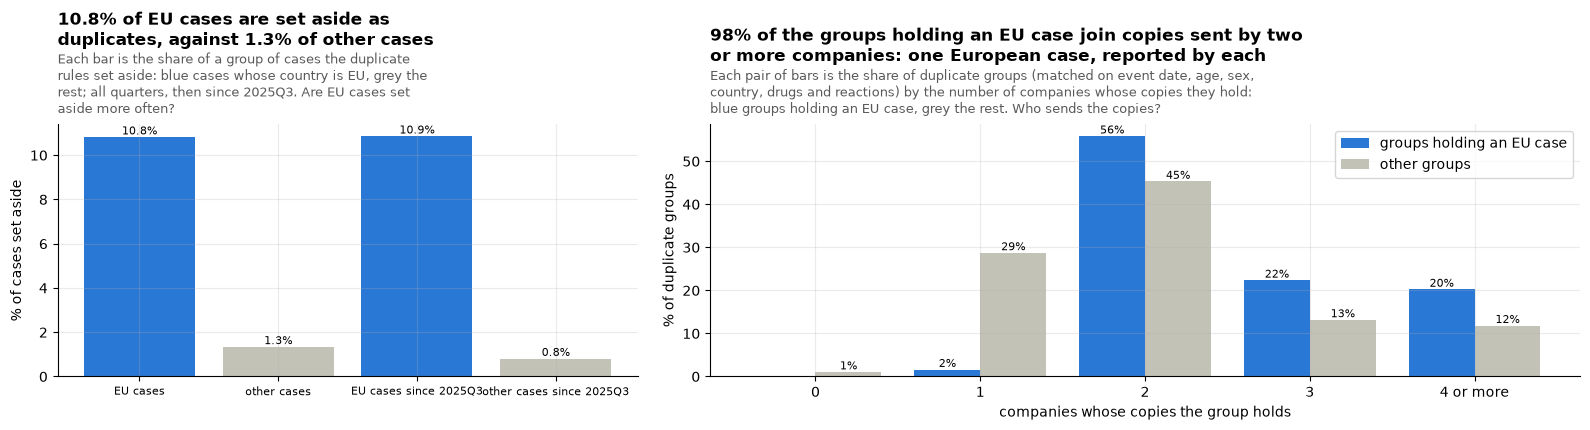

checked twice: cases whose country is EU set aside as duplicates = 17,974
17,974 of the 166,158 cases whose country is EU are set aside. 9,931 duplicate groups hold an EU case; 9,931 of them hold only EU cases, 98% join two or more companies' copies (against 70% of other groups), and 75% give the full event date in every copy.


In [14]:
sa = q(f"""SELECT era_T = 'faers' AND {FDA_COUNTRY} = 'EU' AS eu, count(*) cases, count(*) FILTER (WHERE NOT dup_kept_T) set_aside FROM case_latest_T
          WHERE qnum_T >= 20253 GROUP BY 1""").set_index("eu")
sa_all = q(
    f"SELECT era_T = 'faers' AND {FDA_COUNTRY} = 'EU' AS eu, count(*) cases, count(*) FILTER (WHERE NOT dup_kept_T) set_aside FROM case_latest_T GROUP BY 1"
).set_index("eu")
groups = q(f"""SELECT dup_group_T, count(*) n, count(*) FILTER (WHERE era_T = 'faers' AND {FDA_COUNTRY} = 'EU') n_eu, count(DISTINCT mfr_sndr) companies,
                     bool_and(event_dt_prec_T = 8) full_dates
              FROM case_latest_T WHERE list_contains(dup_rule_T, 'aeolus') GROUP BY 1""")
eu_g = groups[groups.n_eu > 0]
other_g = groups[groups.n_eu == 0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"width_ratios": [0.8, 1.2]})
rates = pd.Series(
    {
        "EU cases": pct(sa_all.set_aside[True], sa_all.cases[True]),
        "other cases": pct(sa_all.set_aside[False], sa_all.cases[False]),
        "EU cases since 2025Q3": pct(sa.set_aside[True], sa.cases[True]),
        "other cases since 2025Q3": pct(sa.set_aside[False], sa.cases[False]),
    }
)
label_bars(
    a1,
    drawn(a1.bar(rates.index, rates.values, color=[SERIES[0], SERIES[7], SERIES[0], SERIES[7]])),
    "{:.1f}%",
)
a1.set_ylabel("% of cases set aside")
a1.tick_params(axis="x", labelsize=8)
title(
    a1,
    f"{rates['EU cases']:.1f}% of EU cases are set aside as duplicates, against {rates['other cases']:.1f}% of other cases",
    "Each bar is the share of a group of cases the duplicate rules set aside: blue cases whose country is EU, grey the rest; all quarters, then since 2025Q3.",
    "Are EU cases set aside more often?",
    width=60,
)
comp = pd.DataFrame(
    {
        "groups holding an EU case": eu_g.companies.clip(upper=4).value_counts().sort_index(),
        "other groups": other_g.companies.clip(upper=4).value_counts().sort_index(),
    }
).fillna(0)
comp = 100 * comp / comp.sum()
x = np.arange(len(comp))
for i, (col, color) in enumerate(
    [("groups holding an EU case", SERIES[0]), ("other groups", SERIES[7])]
):
    label_bars(
        a2, drawn(a2.bar(x + (i - 0.5) * 0.4, comp[col], 0.4, color=color, label=col)), "{:.0f}%"
    )
a2.set_xticks(x)
a2.set_xticklabels([f"{int(k)}" + (" or more" if k == 4 else "") for k in comp.index])
a2.set_xlabel("companies whose copies the group holds")
a2.set_ylabel("% of duplicate groups")
a2.legend()
multi = pct((eu_g.companies > 1).sum(), len(eu_g))
title(
    a2,
    f"{multi:.0f}% of the groups holding an EU case join copies sent by two or more companies: one European case, reported by each",
    "Each pair of bars is the share of duplicate groups (matched on event date, age, sex, country, drugs and reactions) by the number of companies whose copies they hold: "
    "blue groups holding an EU case, grey the rest.",
    "Who sends the copies?",
    width=84,
)
plt.tight_layout()
plt.show()
eu_aside = check(
    "cases whose country is EU set aside as duplicates",
    int(sa_all.set_aside[True]),
    one(f"""SELECT count(*) FROM case_dup_T d JOIN {SECOND} s ON s.case_key_T = d.case_key_T
            WHERE s.era_T = 'faers' AND coalesce(s.occr_country, s.reporter_country) = 'EU' AND NOT d.dup_kept_T"""),
)
all_eu = int((eu_g.n_eu == eu_g.n).sum())
print(
    f"{eu_aside:,} of the {int(sa_all.cases[True]):,} cases whose country is EU are set aside. {len(eu_g):,} duplicate groups hold an EU case; "
    f"{all_eu:,} of them hold only EU cases, {multi:.0f}% join two or more companies' copies (against {pct((other_g.companies > 1).sum(), len(other_g)):.0f}% of other groups), "
    f"and {pct(eu_g.full_dates.sum(), len(eu_g)):.0f}% give the full event date in every copy."
)

### Can an earlier version give back the member state, and how clean is it?

A case that now says EU was often published before with its member state. The charts take the occurrence country, an ISO code other than EU, that an earlier published version of the same case names (the latest such version where there are several), and check it against two other fields of that version: the country prefix of its manufacturer case number and its reporter country. Copies in the same duplicate group are a second source, weighed at the end.

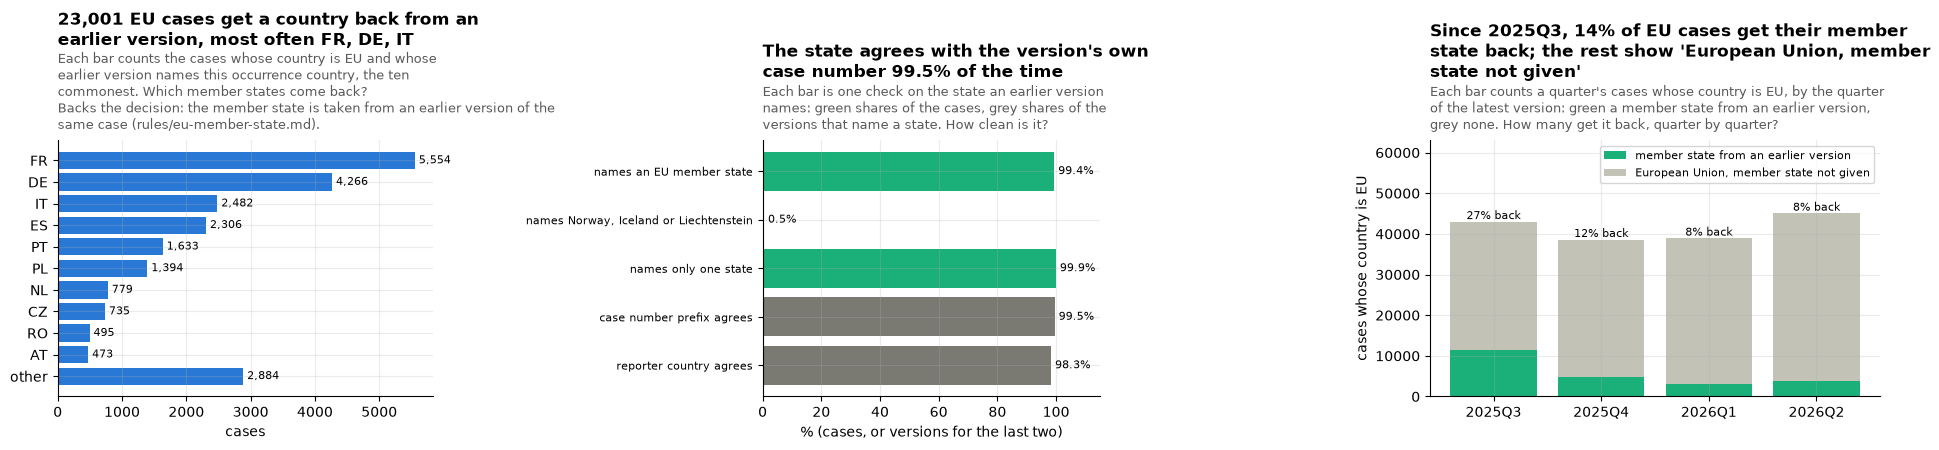

checked twice: EU cases with an earlier version naming the occurrence country = 23,001


23,001 EU cases (14%) have an earlier version naming the occurrence country; 22,078 of the 148,184 shown EU cases. 12 cases name two states across their versions; the latest such version gives the state. Copies in the same duplicate group would add 419 shown cases, less certain, and 1 group names two states. The duplicate rules keep comparing the country as published: compared on the state given back, 424 groups would hold two countries, with 671 cases set aside in them.


In [15]:
con.execute(
    f"""CREATE OR REPLACE TEMP TABLE eu_state_T AS
       SELECT d.caseid, arg_max(d.occr_country, d.qnum_T * 1000 + coalesce(d.caseversion_T, 0)) state, count(DISTINCT d.occr_country) states,
              count(*) versions, count(*) FILTER (WHERE regexp_extract(d.mfr_num, '^([A-Z]{{2}})-', 1) = d.occr_country) number_agrees,
              count(*) FILTER (WHERE regexp_matches(coalesce(d.mfr_num, ''), '^[A-Z]{{2}}-')) number_has_prefix,
              count(*) FILTER (WHERE d.reporter_country = d.occr_country) reporter_agrees
       FROM demo_T d
       WHERE d.era_T = 'faers' AND d.occr_country IN (SELECT code FROM iso2_df) AND d.occr_country <> 'EU'
         AND d.caseid IN (SELECT caseid FROM case_latest_T WHERE era_T = 'faers' AND {FDA_COUNTRY} = 'EU')
       GROUP BY 1"""
)
eu_c = q("""SELECT c.qnum_T, c.quarter_T, c.dup_kept_T, c.dup_group_T, s.state, s.states FROM case_latest_T c
            LEFT JOIN eu_state_T s USING (caseid) WHERE c.era_T = 'faers' AND coalesce(c.occr_country, c.reporter_country) = 'EU'""")
clean = q("""SELECT sum(versions) versions, sum(number_has_prefix) with_prefix, sum(number_agrees) number_agrees, sum(reporter_agrees) reporter_agrees,
                    count(*) FILTER (WHERE states > 1) two_states, count(*) FILTER (WHERE state IN (SELECT code FROM eu27_df)) member,
                    count(*) FILTER (WHERE state IN ('NO', 'IS', 'LI')) eea, count(*) cases FROM eu_state_T""").iloc[
    0
]
fig, (a1, a2, a3) = plt.subplots(
    1, 3, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1, 0.9, 1.2]}
)
st = eu_c.state.value_counts()
top = pd.concat([st.head(10), pd.Series({"other": st.iloc[10:].sum()})])
label_bars(a1, drawn(a1.barh(top.index[::-1], top.values[::-1], color=SERIES[0])), horizontal=True)
a1.set_xlabel("cases")
title(
    a1,
    f"{int(clean.cases):,} EU cases get a country back from an earlier version, most often {', '.join(st.index[:3])}",
    "Each bar counts the cases whose country is EU and whose earlier version names this occurrence country, the ten commonest.",
    "Which member states come back?",
    backs("the member state is taken from an earlier version of the same case", "eu"),
    width=60,
)
checks_ = pd.Series(
    {
        "names an EU member state": pct(clean.member, clean.cases),
        "names Norway, Iceland or Liechtenstein": pct(clean.eea, clean.cases),
        "names only one state": pct(clean.cases - clean.two_states, clean.cases),
        "case number prefix agrees": pct(clean.number_agrees, clean.with_prefix),
        "reporter country agrees": pct(clean.reporter_agrees, clean.versions),
    }
)
label_bars(
    a2,
    drawn(
        a2.barh(
            checks_.index[::-1],
            checks_.values[::-1],
            color=([SERIES[2]] * 3 + [SERIES[6]] * 2)[::-1],
        )
    ),
    "{:.1f}%",
    horizontal=True,
)
a2.set_xlim(0, 115)
a2.set_xlabel("% (cases, or versions for the last two)")
a2.tick_params(axis="y", labelsize=8)
title(
    a2,
    f"The state agrees with the version's own case number {checks_['case number prefix agrees']:.1f}% of the time",
    "Each bar is one check on the state an earlier version names: green shares of the cases, grey shares of the versions that name a state.",
    "How clean is it?",
    width=56,
)
recent = eu_c[eu_c.qnum_T >= 20253].assign(back=lambda d: d.state.notna())
byq = (
    recent.groupby(["qnum_T", "quarter_T"]).back.agg(given_back="sum", total="count").reset_index()
)
xq = np.arange(len(byq))
a3.bar(xq, byq["given_back"], color=SERIES[2], label="member state from an earlier version")
a3.bar(
    xq, byq["total"] - byq["given_back"], bottom=byq["given_back"], color=SERIES[7], label=EU_NAME
)
a3.set_xticks(xq)
a3.set_xticklabels([q_.upper() for q_ in byq.quarter_T])
for i, r in enumerate(byq.itertuples()):
    a3.text(
        i, r.total, f"{pct(r.given_back, r.total):.0f}% back", ha="center", va="bottom", fontsize=8
    )
a3.set_ylim(0, byq["total"].max() * 1.4)
a3.set_ylabel("cases whose country is EU")
a3.legend(fontsize=8, loc="upper right")
back_share = pct(recent.back.sum(), len(recent))
title(
    a3,
    f"Since 2025Q3, {back_share:.0f}% of EU cases get their member state back; the rest show '{EU_NAME}'",
    "Each bar counts a quarter's cases whose country is EU, by the quarter of the latest version: green a member state from an earlier version, grey none.",
    "How many get it back, quarter by quarter?",
    width=70,
)
plt.tight_layout()
plt.show()
back = check(
    "EU cases with an earlier version naming the occurrence country",
    int(eu_c.state.notna().sum()),
    one(f"""SELECT count(*) FROM {SECOND} c WHERE c.era_T = 'faers' AND upper(coalesce(c.occr_country, c.reporter_country)) = 'EU'
            AND EXISTS (SELECT 1 FROM demo_all d JOIN iso2_df i ON i.code = d.occr_country WHERE d.era_T = 'faers' AND d.caseid = c.caseid AND d.occr_country <> 'EU')"""),
)
shown = eu_c[eu_c.dup_kept_T]
mates = q("""WITH e AS (SELECT c.dup_group_T, c.dup_kept_T, s.state FROM case_latest_T c LEFT JOIN eu_state_T s USING (caseid)
                        WHERE c.era_T = 'faers' AND coalesce(c.occr_country, c.reporter_country) = 'EU'),
              g AS (SELECT dup_group_T, count(DISTINCT state) n_states, min(state) state FROM e WHERE dup_group_T IS NOT NULL GROUP BY 1)
         SELECT count(*) FILTER (WHERE e.state IS NULL AND g.state IS NOT NULL) added, count(DISTINCT e.dup_group_T) FILTER (WHERE g.n_states > 1) two
         FROM e LEFT JOIN g USING (dup_group_T) WHERE e.dup_kept_T""").iloc[0]
split = q("""WITH e AS (SELECT c.dup_group_T, c.dup_kept_T, c.dup_rule_T, coalesce(s.state, 'EU') state FROM case_latest_T c LEFT JOIN eu_state_T s USING (caseid)
                        WHERE c.era_T = 'faers' AND coalesce(c.occr_country, c.reporter_country) = 'EU' AND list_contains(c.dup_rule_T, 'aeolus')),
              g AS (SELECT dup_group_T FROM e GROUP BY 1 HAVING count(DISTINCT state) > 1)
         SELECT (SELECT count(*) FROM g) n_groups, count(*) FILTER (WHERE NOT dup_kept_T) set_aside FROM e WHERE dup_group_T IN (SELECT dup_group_T FROM g)""").iloc[
    0
]
print(
    f"{back:,} EU cases ({pct(back, len(eu_c)):.0f}%) have an earlier version naming the occurrence country; {int(shown.state.notna().sum()):,} of the {len(shown):,} shown EU cases. "
    f"{int(clean.two_states)} cases name two states across their versions; the latest such version gives the state. "
    f"Copies in the same duplicate group would add {int(mates.added):,} shown cases, less certain, and {int(mates.two)} group names two states. "
    f"The duplicate rules keep comparing the country as published: compared on the state given back, {int(split.n_groups):,} groups would hold two countries, with {int(split.set_aside):,} cases set aside in them."
)

### How often is the occurrence country empty, and what fills it?

The occurrence country is empty for a share of FAERS cases that rose again from 2022. The release's `country_T` takes the reporter's country there.

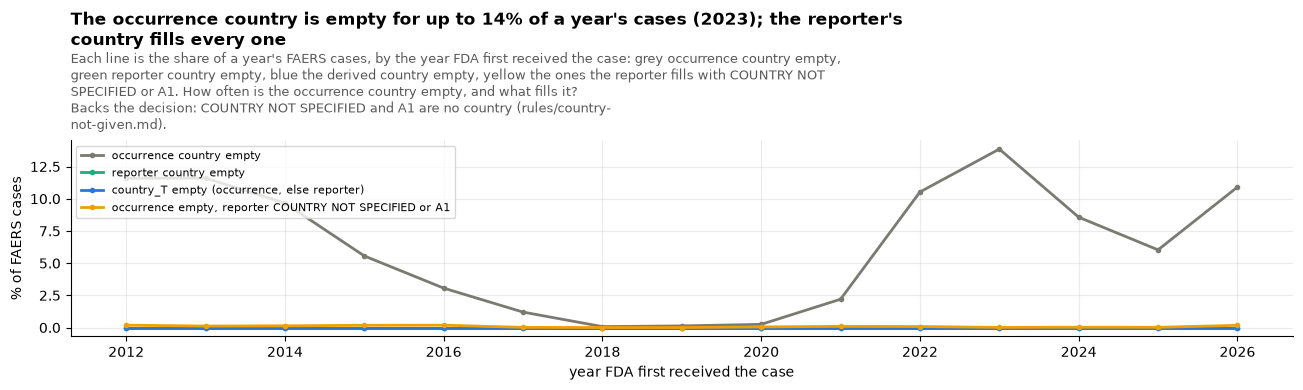

checked twice: FAERS cases with no occurrence country whose reporter country fills it = 980,563
980,563 FAERS cases have no occurrence country, and the reporter's country fills every one, so before the decisions no FAERS case was without a country_T. As decided, COUNTRY NOT SPECIFIED and A1 are no country, so 12,739 FAERS cases have none; with the EU cases given their member state back, 35,805 FAERS cases have a country_T other than the occurrence country, else the reporter's.


In [16]:
gap = q(f"""SELECT init_year_T yr, 100 * avg((occr_country IS NULL)::INT) occurrence, 100 * avg((reporter_country IS NULL)::INT) reporter,
                  100 * avg(({FDA_COUNTRY} IS NULL)::INT) country_T, 100 * avg((occr_country IS NULL AND reporter_country IN ('COUNTRY NOT SPECIFIED', 'A1'))::INT) not_specified
           FROM case_latest_T WHERE era_T = 'faers' AND init_year_T >= 2012 GROUP BY 1 ORDER BY 1""")
fig, ax = plt.subplots(figsize=(13, 4))
for col, color, label in [
    ("occurrence", SERIES[6], "occurrence country empty"),
    ("reporter", SERIES[2], "reporter country empty"),
    ("country_T", SERIES[0], "country_T empty (occurrence, else reporter)"),
    ("not_specified", SERIES[3], "occurrence empty, reporter COUNTRY NOT SPECIFIED or A1"),
]:
    ax.plot(gap.yr, gap[col], color=color, label=label, marker="o", ms=3)
ax.set_xlabel("year FDA first received the case")
ax.set_ylabel("% of FAERS cases")
ax.legend(fontsize=8, loc="upper left")
peak = gap.loc[gap.occurrence.idxmax()]
title(
    ax,
    f"The occurrence country is empty for up to {peak.occurrence:.0f}% of a year's cases ({int(peak.yr)}); the reporter's country fills every one",
    "Each line is the share of a year's FAERS cases, by the year FDA first received the case: grey occurrence country empty, green reporter country empty, "
    "blue the derived country empty, yellow the ones the reporter fills with COUNTRY NOT SPECIFIED or A1.",
    "How often is the occurrence country empty, and what fills it?",
    backs("COUNTRY NOT SPECIFIED and A1 are no country", "country"),
    width=120,
)
plt.tight_layout()
plt.show()
differs = one(
    f"SELECT count(*) FROM case_latest_T WHERE era_T = 'faers' AND country_T IS DISTINCT FROM {FDA_COUNTRY}"
)
filled = check(
    "FAERS cases with no occurrence country whose reporter country fills it",
    one(
        "SELECT count(*) FROM case_latest_T WHERE era_T = 'faers' AND occr_country IS NULL AND reporter_country IS NOT NULL"
    ),
    one(
        f"SELECT count(*) FROM {SECOND} WHERE era_T = 'faers' AND occr_country IS NULL AND length(reporter_country) > 0"
    ),
)
no_country = one(
    f"SELECT count(*) FROM case_latest_T WHERE era_T = 'faers' AND {COUNTRY_RULED} IS NULL"
)
print(
    f"{filled:,} FAERS cases have no occurrence country, and the reporter's country fills every one, so before the decisions no FAERS case was without a country_T. "
    f"As decided, COUNTRY NOT SPECIFIED and A1 are no country, so {no_country:,} FAERS cases have none; with the EU cases given their member state back, "
    f"{differs:,} FAERS cases have a country_T other than the occurrence country, else the reporter's."
)

### What else is left, and which field should come first?

`COUNTRY NOT SPECIFIED` is FDA's text for "no country" in `reporter_country` (FDA's FAQ, question 21); `A1` is not a country code either. The rest are a few retired or user-assigned codes. Where both fields name a country, which one wins matters only where they differ.

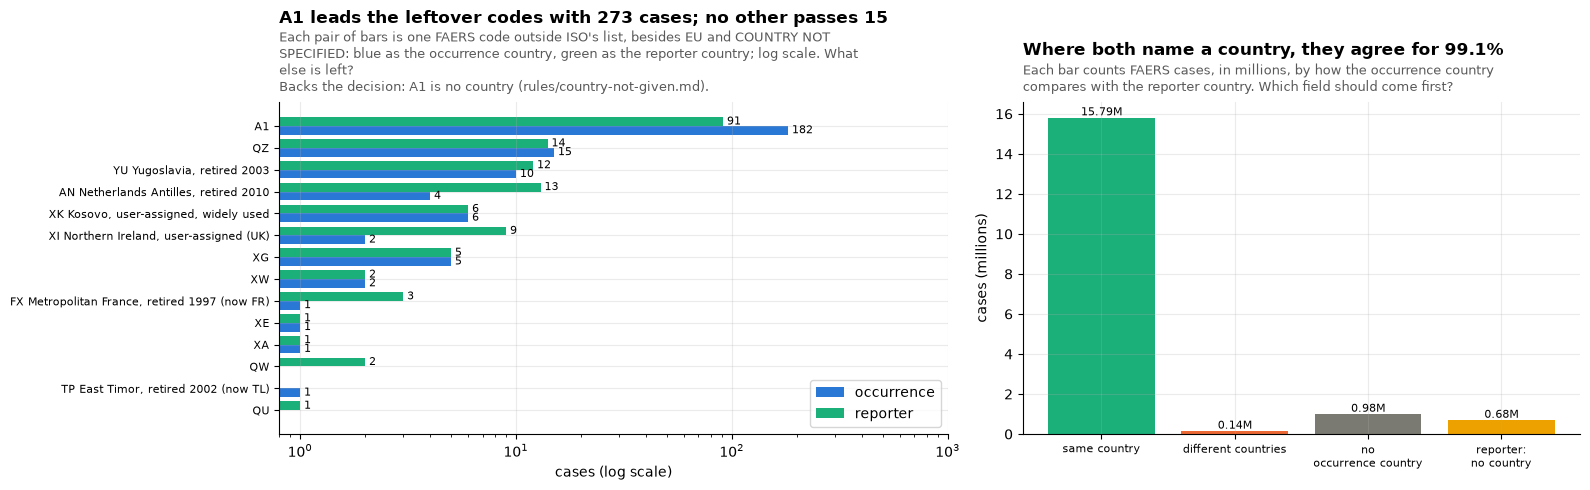

checked twice: FAERS cases whose country is COUNTRY NOT SPECIFIED or A1 (no country as decided) = 12,804
12,804 cases have COUNTRY NOT SPECIFIED or A1 as their country; 65 of the A1 cases name a real reporter country, which then becomes their country. The two fields differ for 135,500 FAERS cases; the commonest pairs (event / reporter): US / GB 19,305, FR / NL 6,853, FR / GB 5,128, DE / GB 3,484. AERS cases whose country is not an ISO code: CS 35, YU 32, EU 26, AN 16.


**What section 7 shows**, one item per chart:

- **The occurrence country, quarter by quarter.** *Shows:* since 2025Q3, 161,362 of the 1,529,534 cases published (10.5%, about one in ten) give EU, not a member state; before, EU is almost absent; 96% of them start their manufacturer number with EU- where it used to start with the country, and 16,013 were first received before 2025. *Point:* something upstream, most likely how European reports now reach FDA, hides the member state, on follow-ups too. *So what:* EU stays as FDA wrote it and is named "European Union, member state not given"; this is one of the methods-page cards.
- **The reporter country, quarter by quarter.** *Shows:* it switches to EU at the same time (10.6% since 2025Q3). *Point:* the reporter field cannot give the member state back. *So what:* only an earlier version can.
- **Set aside as duplicates.** *Shows:* 10.8% of EU cases are set aside, against 1.3% of other cases. *Point:* EU cases are duplicated far more often. *So what:* the next chart says why; nothing to fix.
- **Who sends the copies.** *Shows:* 9,931 duplicate groups hold an EU case, 9,931 hold only EU cases, 98% join copies from two or more companies (against 70% of other groups) and 75% give the full event date in every copy. *Point:* one European case, sent to FDA by several companies; the matches are real. *So what:* the duplicate rules are doing their job; the high share is FDA's data.
- **Which member states come back.** *Shows:* 23,001 EU cases (14%) have an earlier version that names the occurrence country, 22,078 of the 148,184 shown; most often FR 5,554, DE 4,266, IT 2,482, ES 2,306, PT 1,633, PL 1,394. *Point:* about one shown EU case in seven can have its member state back from FDA's own data. *So what:* the member state is taken from an earlier version of the same case and marked as such.
- **How clean it is.** *Shows:* 99.4% name an EU member state and 0.5% Norway, Iceland or Liechtenstein; 12 name two states (the latest version's is taken); the version's own case number agrees on the country 99.5% of the time and its reporter country 98.3%. *Point:* the state comes from the same case and agrees with the case's other fields. *So what:* safe to show; copies in the same duplicate group would add only 419 shown cases, less certain, and 1 group names two states, so they are not used. The duplicate rules keep comparing the country as published: compared on the state given back, 424 groups of copies of one European case would split.
- **Quarter by quarter.** *Shows:* since 2025Q3, 14% of EU cases get their member state back. *Point:* the rest have no member state anywhere in FDA's files. *So what:* they show "European Union, member state not given".
- **The occurrence country empty.** *Shows:* up to 14% of a year's FAERS cases (2023) give no occurrence country, but the reporter's country is never empty, so the release's country is never empty for a FAERS case; the reporter's value there is COUNTRY NOT SPECIFIED or A1 for at most 0.2% of a year's cases. *Point:* the reporter field fills the gap, mostly with a real country. *So what:* the occurrence country stays first, the reporter's second; as decided, 12,739 FAERS cases are left with no country.
- **What else is left.** *Shows:* A1 leads the leftover codes; retired codes (YU, AN, TP, FX) and user-assigned ones (XK Kosovo, XI Northern Ireland) are rare; 12,804 cases have COUNTRY NOT SPECIFIED or A1 as their country. *Point:* COUNTRY NOT SPECIFIED and A1 are not countries; the rest are rare enough to show as written. *So what:* COUNTRY NOT SPECIFIED and A1 are no country, as DiAna does; FDA's own value stays in the FAERS columns.
- **Which field comes first.** *Shows:* where both fields name a country they agree for 99.1% of FAERS cases; where they differ, the commonest pairs have the reporter in GB or NL (US / GB, FR / NL, FR / GB). *Point:* the occurrence country is the one that describes the event. *So what:* the occurrence country stays first.


In [17]:
MEANING = {
    "YU": "Yugoslavia, retired 2003",
    "AN": "Netherlands Antilles, retired 2010",
    "TP": "East Timor, retired 2002 (now TL)",
    "FX": "Metropolitan France, retired 1997 (now FR)",
    "CS": "Serbia and Montenegro, retired 2006",
    "XK": "Kosovo, user-assigned, widely used",
    "XI": "Northern Ireland, user-assigned (UK)",
}
left = q("""SELECT 'occurrence' col, occr_country code, count(*) cases FROM case_latest_T
            WHERE era_T = 'faers' AND occr_country NOT IN (SELECT code FROM iso2_df) AND occr_country NOT IN ('EU', 'COUNTRY NOT SPECIFIED') GROUP BY ALL
            UNION ALL
            SELECT 'reporter', reporter_country, count(*) FROM case_latest_T
            WHERE era_T = 'faers' AND reporter_country NOT IN (SELECT code FROM iso2_df) AND reporter_country NOT IN ('EU', 'COUNTRY NOT SPECIFIED') GROUP BY ALL""")
oc = (
    q("""SELECT CASE WHEN occr_country IS NULL THEN 'no occurrence country' WHEN reporter_country IN ('COUNTRY NOT SPECIFIED', 'A1') THEN 'reporter: no country'
                      WHEN occr_country = reporter_country THEN 'same country' ELSE 'different countries' END k, count(*) cases
          FROM case_latest_T WHERE era_T = 'faers' GROUP BY 1""")
    .set_index("k")
    .cases.reindex(
        ["same country", "different countries", "no occurrence country", "reporter: no country"]
    )
    .fillna(0)
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1]})
pv = left.pivot_table(index="code", columns="col", values="cases", aggfunc="sum").fillna(0)
pv = pv.loc[pv.sum(axis=1).sort_values().index]
y = np.arange(len(pv))
h = 0.4
for i, (col, color) in enumerate([("occurrence", SERIES[0]), ("reporter", SERIES[2])]):
    if col in pv:
        label_bars(
            a1,
            drawn(a1.barh(y + (i - 0.5) * h, pv[col], h, color=color, label=col)),
            horizontal=True,
        )
a1.set_yticks(y)
a1.set_yticklabels([f"{c} {MEANING.get(c, '')}".strip() for c in pv.index], fontsize=8)
a1.set_xscale("log")
a1.set_xlim(0.8, 1e3)
a1.set_xlabel("cases (log scale)")
a1.legend(loc="lower right")
title(
    a1,
    f"A1 leads the leftover codes with {int(pv.loc['A1'].sum()) if 'A1' in pv.index else 0} cases; no other passes {int(pv.drop(index='A1', errors='ignore').values.max())}",
    "Each pair of bars is one FAERS code outside ISO's list, besides EU and COUNTRY NOT SPECIFIED: blue as the occurrence country, green as the reporter country; log scale.",
    "What else is left?",
    backs("A1 is no country", "country"),
    width=89,
)
label_bars(
    a2,
    drawn(a2.bar(oc.index, oc.values / 1e6, color=[SERIES[2], SERIES[1], SERIES[6], SERIES[3]])),
    "{:.2f}M",
)
a2.set_xticks(range(len(oc)))
a2.set_xticklabels(
    [k.replace(": ", ":\n").replace(" occurrence", "\noccurrence") for k in oc.index], fontsize=8
)
a2.set_ylabel("cases (millions)")
title(
    a2,
    f"Where both name a country, they agree for {pct(oc['same country'], oc['same country'] + oc['different countries']):.1f}%",
    "Each bar counts FAERS cases, in millions, by how the occurrence country compares with the reporter country.",
    "Which field should come first?",
    width=72,
)
plt.tight_layout()
plt.show()
cns = check(
    "FAERS cases whose country is COUNTRY NOT SPECIFIED or A1 (no country as decided)",
    one(
        f"SELECT count(*) FROM case_latest_T WHERE era_T = 'faers' AND {FDA_COUNTRY} IN ('COUNTRY NOT SPECIFIED', 'A1')"
    ),
    one(f"""SELECT count(*) FROM {SECOND} WHERE era_T = 'faers' AND (occr_country IN ('COUNTRY NOT SPECIFIED', 'A1')
                                          OR (occr_country IS NULL AND reporter_country IN ('COUNTRY NOT SPECIFIED', 'A1')))"""),
)
a1_other = one(
    "SELECT count(*) FROM case_latest_T WHERE occr_country = 'A1' AND reporter_country NOT IN ('COUNTRY NOT SPECIFIED', 'A1')"
)
pairs = q("""SELECT occr_country || ' / ' || reporter_country pair, count(*) cases FROM case_latest_T
             WHERE era_T = 'faers' AND occr_country <> reporter_country AND reporter_country NOT IN ('COUNTRY NOT SPECIFIED', 'A1') GROUP BY 1 ORDER BY 2 DESC LIMIT 4""")
legacy_non_iso = q(
    "SELECT country_T, count(*) cases FROM case_latest_T WHERE era_T = 'legacy' AND country_T NOT IN (SELECT code FROM iso2_df) GROUP BY 1 ORDER BY 2 DESC"
)
print(
    f"{cns:,} cases have COUNTRY NOT SPECIFIED or A1 as their country; {a1_other} of the A1 cases name a real reporter country, which then becomes their country. "
    f"The two fields differ for {int(oc['different countries']):,} FAERS cases; the commonest pairs (event / reporter): "
    + ", ".join(f"{r.pair} {r.cases:,}" for r in pairs.itertuples())
    + ". AERS cases whose country is not an ISO code: "
    + (", ".join(f"{r.country_T} {r.cases:,}" for r in legacy_non_iso.itertuples()) or "none")
    + "."
)
say(f"""**What section 7 shows**, one item per chart:

- **The occurrence country, quarter by quarter.** *Shows:* since 2025Q3, {int(eu_recent.n):,} of the {int(eu_recent.total):,} cases published ({pct(eu_recent.n, eu_recent.total):.1f}%, about one in ten) give EU, not a member state; before, EU is almost absent; {pct(eu_recent.n_mfr_eu, eu_recent.n):.0f}% of them start their manufacturer number with EU- where it used to start with the country, and {first_before:,} were first received before 2025. *Point:* something upstream, most likely how European reports now reach FDA, hides the member state, on follow-ups too. *So what:* EU stays as FDA wrote it and is named "{EU_NAME}"; this is one of the methods-page cards.
- **The reporter country, quarter by quarter.** *Shows:* it switches to EU at the same time ({pct(eu_recent.r, eu_recent.total):.1f}% since 2025Q3). *Point:* the reporter field cannot give the member state back. *So what:* only an earlier version can.
- **Set aside as duplicates.** *Shows:* {rates["EU cases"]:.1f}% of EU cases are set aside, against {rates["other cases"]:.1f}% of other cases. *Point:* EU cases are duplicated far more often. *So what:* the next chart says why; nothing to fix.
- **Who sends the copies.** *Shows:* {len(eu_g):,} duplicate groups hold an EU case, {all_eu:,} hold only EU cases, {multi:.0f}% join copies from two or more companies (against {pct((other_g.companies > 1).sum(), len(other_g)):.0f}% of other groups) and {pct(eu_g.full_dates.sum(), len(eu_g)):.0f}% give the full event date in every copy. *Point:* one European case, sent to FDA by several companies; the matches are real. *So what:* the duplicate rules are doing their job; the high share is FDA's data.
- **Which member states come back.** *Shows:* {back:,} EU cases ({pct(back, len(eu_c)):.0f}%) have an earlier version that names the occurrence country, {int(shown.state.notna().sum()):,} of the {len(shown):,} shown; most often {", ".join(f"{s} {n:,}" for s, n in st.head(6).items())}. *Point:* about one shown EU case in seven can have its member state back from FDA's own data. *So what:* the member state is taken from an earlier version of the same case and marked as such.
- **How clean it is.** *Shows:* {pct(clean.member, clean.cases):.1f}% name an EU member state and {pct(clean.eea, clean.cases):.1f}% Norway, Iceland or Liechtenstein; {int(clean.two_states)} name two states (the latest version's is taken); the version's own case number agrees on the country {checks_["case number prefix agrees"]:.1f}% of the time and its reporter country {checks_["reporter country agrees"]:.1f}%. *Point:* the state comes from the same case and agrees with the case's other fields. *So what:* safe to show; copies in the same duplicate group would add only {int(mates.added):,} shown cases, less certain, and {int(mates.two)} group names two states, so they are not used. The duplicate rules keep comparing the country as published: compared on the state given back, {int(split.n_groups):,} groups of copies of one European case would split.
- **Quarter by quarter.** *Shows:* since 2025Q3, {back_share:.0f}% of EU cases get their member state back. *Point:* the rest have no member state anywhere in FDA's files. *So what:* they show "{EU_NAME}".
- **The occurrence country empty.** *Shows:* up to {peak.occurrence:.0f}% of a year's FAERS cases ({int(peak.yr)}) give no occurrence country, but the reporter's country is never empty, so the release's country is never empty for a FAERS case; the reporter's value there is COUNTRY NOT SPECIFIED or A1 for at most {gap.not_specified.max():.1f}% of a year's cases. *Point:* the reporter field fills the gap, mostly with a real country. *So what:* the occurrence country stays first, the reporter's second; as decided, {no_country:,} FAERS cases are left with no country.
- **What else is left.** *Shows:* A1 leads the leftover codes; retired codes (YU, AN, TP, FX) and user-assigned ones (XK Kosovo, XI Northern Ireland) are rare; {cns:,} cases have COUNTRY NOT SPECIFIED or A1 as their country. *Point:* COUNTRY NOT SPECIFIED and A1 are not countries; the rest are rare enough to show as written. *So what:* COUNTRY NOT SPECIFIED and A1 are no country, as DiAna does; FDA's own value stays in the FAERS columns.
- **Which field comes first.** *Shows:* where both fields name a country they agree for {pct(oc["same country"], oc["same country"] + oc["different countries"]):.1f}% of FAERS cases; where they differ, the commonest pairs have the reporter in GB or NL ({", ".join(pairs.pair.head(3))}). *Point:* the occurrence country is the one that describes the event. *So what:* the occurrence country stays first.
""")

## 8. Which cases kept change

These decisions change derived values, and two of the duplicate rules read them. The rule that matches on event date, age, sex, country, drugs and reactions (the AEOLUS rule) needs a country, so a case that matched only through `COUNTRY NOT SPECIFIED` or `A1` no longer matches. The rule that matches on the manufacturer's case number skips a group whose ages differ by more than its gap, so an age the decisions add or remove can change that. This section counts both; a release built with the decisions states the exact counts in its changelog.

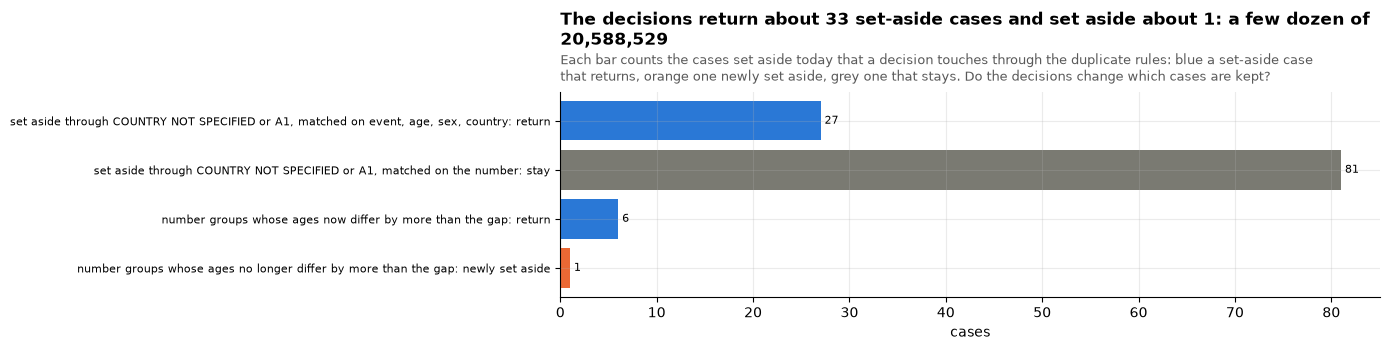

checked twice: probable duplicates whose country is COUNTRY NOT SPECIFIED or A1, matched on event, age, sex and country = 54
54 probable duplicates depend on COUNTRY NOT SPECIFIED or A1 through the event rule; 27 of them are set aside and return. The 240 matched by the manufacturer number stay matched (81 set aside). 119 set-aside cases sit in 117 number groups where a decision changes an age; the age guard's outcome changes for 7 of those groups (14 cases). The member state given back to EU cases changes no match: the duplicate rules compare the country as published (section 7).


**What section 8 shows**, one chart:

- **Cases kept.** *Shows:* 27 set-aside cases matched only through COUNTRY NOT SPECIFIED or A1 return; the 81 the manufacturer number matched stay set aside; 119 set-aside cases sit in number groups where a decision changes an age, but the age guard's outcome changes for only 7 groups, returning 6 cases and setting aside 1. *Point:* the decisions are about values, and touch which cases are kept only at the margin. *So what:* the release built with them is a new data release with a changelog entry giving its counts before and after.


In [18]:
gap_years = 2  # the number rule's age gap (rules/dup-manufacturer-number.md)
# Before the decisions COUNTRY NOT SPECIFIED and A1 were a country, so the AEOLUS rule compared them. Its key for those
# cases, written out as the duplicate rules spell it: event date, age, unit, sex, country, and the case's drug and
# reaction sets (distinct, sorted, joined with |). Cases sharing it were set aside, all but one copy per group.
con.execute(f"""CREATE OR REPLACE TEMP TABLE cns_key_T AS
    WITH c AS (SELECT era_T, primaryid, quarter_T, case_key_T, dup_kept_T, probable_duplicate_T,
                      concat_ws('|', event_dt, age, age_cod, sex, {FDA_COUNTRY}) head,
                      event_dt IS NOT NULL AND age IS NOT NULL AND age_cod IS NOT NULL AND sex IS NOT NULL complete
               FROM case_latest_T WHERE era_T = 'faers' AND {FDA_COUNTRY} IN ('COUNTRY NOT SPECIFIED', 'A1')),
         d AS (SELECT era_T, primaryid, quarter_T, string_agg(DISTINCT drugname_norm_T, '|' ORDER BY drugname_norm_T) s
               FROM drug_latest_T WHERE drugname_norm_T IS NOT NULL AND primaryid IN (SELECT primaryid FROM c) GROUP BY ALL),
         r AS (SELECT era_T, primaryid, quarter_T, string_agg(DISTINCT pt_norm_T, '|' ORDER BY pt_norm_T) s
               FROM reac_latest_T WHERE pt_norm_T IS NOT NULL AND primaryid IN (SELECT primaryid FROM c) GROUP BY ALL)
    SELECT c.case_key_T, c.dup_kept_T, c.probable_duplicate_T,
           CASE WHEN complete AND d.s IS NOT NULL AND r.s IS NOT NULL THEN concat_ws('|', head, d.s, r.s) END k
    FROM c LEFT JOIN d USING (era_T, primaryid, quarter_T) LEFT JOIN r USING (era_T, primaryid, quarter_T)""")
# matched through COUNTRY NOT SPECIFIED or A1: those set aside then (all but one per group) that the release keeps
# return; matched on the number: the release's own flags, which the decision does not touch
ctry = q("""WITH g AS (SELECT k FROM cns_key_T WHERE k IS NOT NULL GROUP BY 1 HAVING count(*) > 1)
            SELECT true aeolus, count(*) flagged, count(*) - count(DISTINCT k) - count(*) FILTER (WHERE NOT dup_kept_T) set_aside
            FROM cns_key_T WHERE k IN (SELECT k FROM g)
            UNION ALL
            SELECT false, count(*), count(*) FILTER (WHERE NOT dup_kept_T) FROM cns_key_T
            WHERE probable_duplicate_T AND coalesce(k NOT IN (SELECT k FROM g), true)""").set_index(
    "aeolus"
)
con.execute(f"""CREATE OR REPLACE TEMP TABLE number_ages_T AS
                SELECT d.dup_number_key_T k, d.dup_kept_T, {OLD_AGE} held, {AGE_RULED} decided, c.sex
                FROM case_dup_T d JOIN case_latest_T c USING (case_key_T)
                WHERE d.dup_number_key_T IN (SELECT dup_number_key_T FROM case_dup_T WHERE dup_number_key_T IS NOT NULL GROUP BY 1 HAVING count(*) > 1)""")
touched = q("""WITH g AS (SELECT k FROM number_ages_T GROUP BY 1 HAVING bool_or(coalesce(decided, -1) <> coalesce(held, -1)))
               SELECT count(DISTINCT k) n_groups, count(*) FILTER (WHERE NOT dup_kept_T) set_aside FROM number_ages_T WHERE k IN (SELECT k FROM g)""").iloc[
    0
]
guard = q(f"""WITH k AS (SELECT * FROM number_ages_T),
                   g AS (SELECT k, count(*) n, coalesce(max(held) - min(held) > {gap_years}, false) skipped_before, coalesce(max(decided) - min(decided) > {gap_years}, false) skipped_after,
                                count(*) FILTER (WHERE NOT dup_kept_T) set_aside, count(DISTINCT sex) FILTER (WHERE sex IN ('F', 'M')) = 2 sexes
                         FROM k GROUP BY 1 HAVING count(*) > 1)
              SELECT skipped_before, skipped_after, count(*) n_groups, sum(n) cases, sum(set_aside) set_aside FROM g WHERE skipped_before <> skipped_after AND NOT sexes GROUP BY ALL""")
# a group the guard skips only after the decisions had all but one copy set aside before; the release keeps those
# it no longer sets aside
back = guard[guard.skipped_after & ~guard.skipped_before]
returns = int(back.cases.sum() - back.n_groups.sum() - back.set_aside.sum())
joins = int(
    guard[guard.skipped_before & ~guard.skipped_after].cases.sum()
    - guard[guard.skipped_before & ~guard.skipped_after].n_groups.sum()
)
# the cases set aside in those groups before the decisions: the release's, with those that return, without those newly set aside
touched["set_aside"] = int(touched.set_aside) + returns - joins
rows = pd.Series(
    {
        "set aside through COUNTRY NOT SPECIFIED or A1, matched on event, age, sex, country: return": int(
            ctry.set_aside.get(True, 0)
        ),
        "set aside through COUNTRY NOT SPECIFIED or A1, matched on the number: stay": int(
            ctry.set_aside.get(False, 0)
        ),
        "number groups whose ages now differ by more than the gap: return": returns,
        "number groups whose ages no longer differ by more than the gap: newly set aside": joins,
    }
)
fig, ax = plt.subplots(figsize=(14, 3.6))
label_bars(
    ax,
    ax.barh(
        rows.index[::-1], rows.values[::-1], color=[SERIES[1], SERIES[0], SERIES[6], SERIES[0]]
    ),
    horizontal=True,
)
ax.set_xlabel("cases")
ax.tick_params(axis="y", labelsize=8)
title(
    ax,
    f"The decisions return about {rows.iloc[0] + returns:,} set-aside cases and set aside about {joins:,}: a few dozen of {N_CASES:,}",
    "Each bar counts the cases set aside today that a decision touches through the duplicate rules: blue a set-aside case that returns, orange one newly set aside, grey one that stays.",
    "Do the decisions change which cases are kept?",
    width=120,
)
plt.tight_layout()
plt.show()
cns_flagged = check(
    "probable duplicates whose country is COUNTRY NOT SPECIFIED or A1, matched on event, age, sex and country",
    int(ctry.flagged.get(True, 0)),
    one(f"""WITH s AS (SELECT s.* FROM {SECOND} s WHERE s.era_T = 'faers' AND coalesce(s.occr_country, s.reporter_country) IN ('COUNTRY NOT SPECIFIED', 'A1')
                                    AND s.event_dt IS NOT NULL AND s.age IS NOT NULL AND s.age_cod IS NOT NULL AND s.sex IS NOT NULL),
                 d AS (SELECT primaryid, quarter_T, list_sort(list_distinct(list(drugname_norm_T) FILTER (WHERE drugname_norm_T IS NOT NULL))) v
                       FROM drug_latest_T WHERE era_T = 'faers' AND primaryid IN (SELECT primaryid FROM s) GROUP BY ALL),
                 r AS (SELECT primaryid, quarter_T, list_sort(list_distinct(list(pt_norm_T) FILTER (WHERE pt_norm_T IS NOT NULL))) v
                       FROM reac_latest_T WHERE era_T = 'faers' AND primaryid IN (SELECT primaryid FROM s) GROUP BY ALL),
                 x AS (SELECT s.case_key_T, s.event_dt, s.age, s.age_cod, s.sex, coalesce(s.occr_country, s.reporter_country) c, d.v drugs, r.v pts
                       FROM s JOIN d USING (primaryid, quarter_T) JOIN r USING (primaryid, quarter_T) WHERE len(d.v) > 0 AND len(r.v) > 0)
            SELECT count(*) FROM x WHERE EXISTS (SELECT 1 FROM x y WHERE y.case_key_T <> x.case_key_T AND y.event_dt = x.event_dt AND y.age = x.age
                                                 AND y.age_cod = x.age_cod AND y.sex = x.sex AND y.c = x.c AND y.drugs = x.drugs AND y.pts = x.pts)"""),
)
print(
    f"{cns_flagged} probable duplicates depend on COUNTRY NOT SPECIFIED or A1 through the event rule; {int(ctry.set_aside.get(True, 0))} of them are set aside and return. "
    f"The {int(ctry.flagged.get(False, 0))} matched by the manufacturer number stay matched ({int(ctry.set_aside.get(False, 0))} set aside). "
    f"{int(touched.set_aside)} set-aside cases sit in {int(touched.n_groups)} number groups where a decision changes an age; the age guard's outcome changes for {int(guard.n_groups.sum())} of those groups ({int(guard.cases.sum())} cases). "
    f"The member state given back to EU cases changes no match: the duplicate rules compare the country as published (section 7)."
)
say(f"""**What section 8 shows**, one chart:

- **Cases kept.** *Shows:* {int(ctry.set_aside.get(True, 0))} set-aside cases matched only through COUNTRY NOT SPECIFIED or A1 return; the {int(ctry.set_aside.get(False, 0))} the manufacturer number matched stay set aside; {int(touched.set_aside)} set-aside cases sit in number groups where a decision changes an age, but the age guard's outcome changes for only {int(guard.n_groups.sum())} groups, returning {returns} cases and setting aside {joins}. *Point:* the decisions are about values, and touch which cases are kept only at the margin. *So what:* the release built with them is a new data release with a changelog entry giving its counts before and after.
""")

## 9. What was decided

Every decision changes a derived value, ending in `_T`; FDA's own values stay beside it, unchanged. Each decision lives in a rule file with its numbers, and the methods page says why in a sentence.

- **Sex.** A case's sex is F or M as FDA wrote it; every other code (NS, UNK, P, I, T, the stray YR) and an empty field are "not given". FDA's letter stays in `sex` for anyone who wants UNK apart from empty.
- **Age units.** An age with no unit is in years. MIN and SEC are converted like the other units. The age is kept exact, never rounded to whole years. A unit is not borrowed from another version of the case.
- **Negative ages.** A negative age is no age: it marks a child exposed before birth, and the methods page says so.
- **The oldest ages.** An age over 122 years, the human record, is no age.
- **The number reader.** A number written `.8`, `60.` or with spaces around it is read as the number it is, for ages and weights alike, in both apps. This was a bug.
- **Age bands.** Both apps use the same ten bands: Under 28 days, 28 days to under 2, Under 1 with the exact age not given, 2 to 11, 12 to 17, 18 to 64, 65 to 74, 75 to 84, 85 and over, and Not given. An age given as 0 years goes under 28 days when the sender's group says neonate, to 28 days to under 2 when it says infant, and otherwise to "Under 1, exact age not given": being right matters more than matching DiAna, which counts 0 years as 0 days.
- **Weight.** Pounds convert by the exact factor, 0.45359237. A weight of zero, over 635 kg, with no unit or in a unit FDA does not define is no weight.
- **Country.** `COUNTRY NOT SPECIFIED` and `A1` are no country. `EU` is named "European Union, member state not given", unless an earlier version of the same case names the member state: then that state is shown, marked as taken from an earlier version. Copies of the case in the same duplicate group are not used, since they add few cases and are less certain.

## 10. Methods-page cards from this notebook

The cards below are computed by the same functions the release build calls (`src/open_altio/faers/insights/cards`), so the chart data on the methods page is reproducible from this code. Each card is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT`) for checking; the release carries them in `methods.json`.

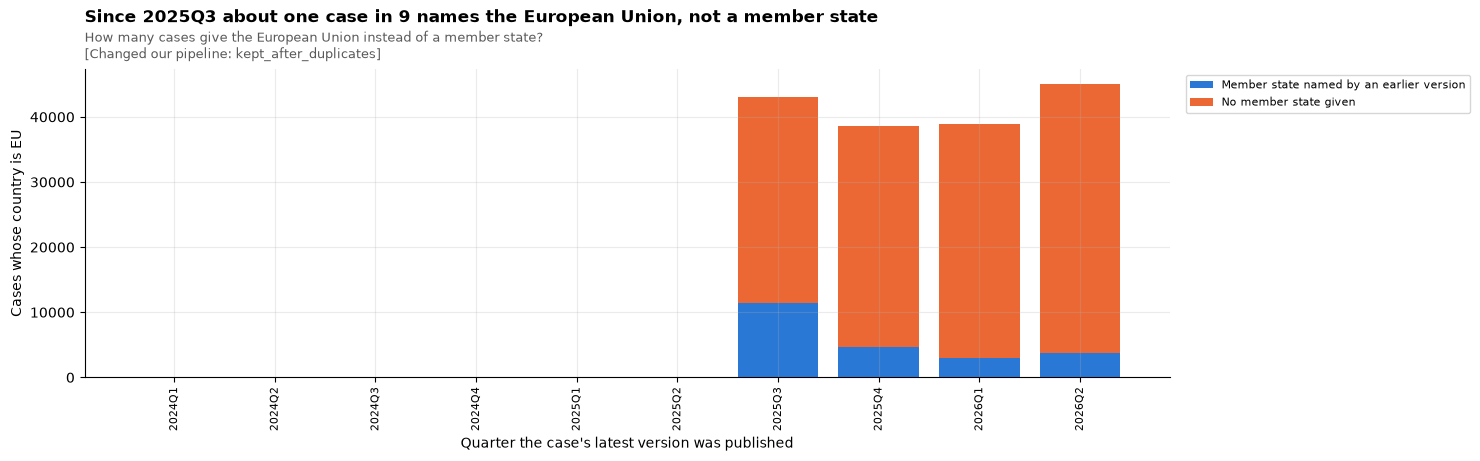

Since 2025Q3, 165,505 of the 1,529,534 cases published (11%) give EU as their country instead of the member state, and 96% of them start the manufacturer's case number with EU- where it used to start with the country; before, EU is almost absent. For 23,001 of them an earlier version of the same case still names the member state, which Open Altio shows, marked as from an earlier version; the rest show "European Union, member state not given".


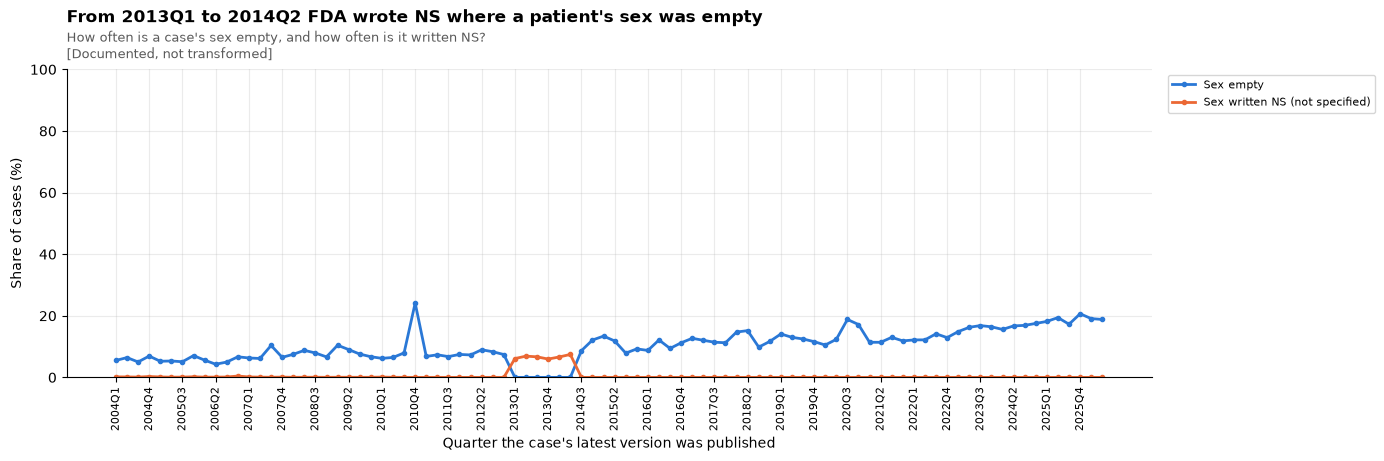

From 2013Q1 to 2014Q2, 7% of cases say NS (not specified) and 0 of 1,194,900 have an empty sex, while before and after NS is almost absent and the field is simply left empty. A count of cases with no sex that leaves NS out misses 78,652 cases in those quarters; Open Altio reads NS, UNK and an empty field alike as sex not given, and keeps FDA's letter beside it.


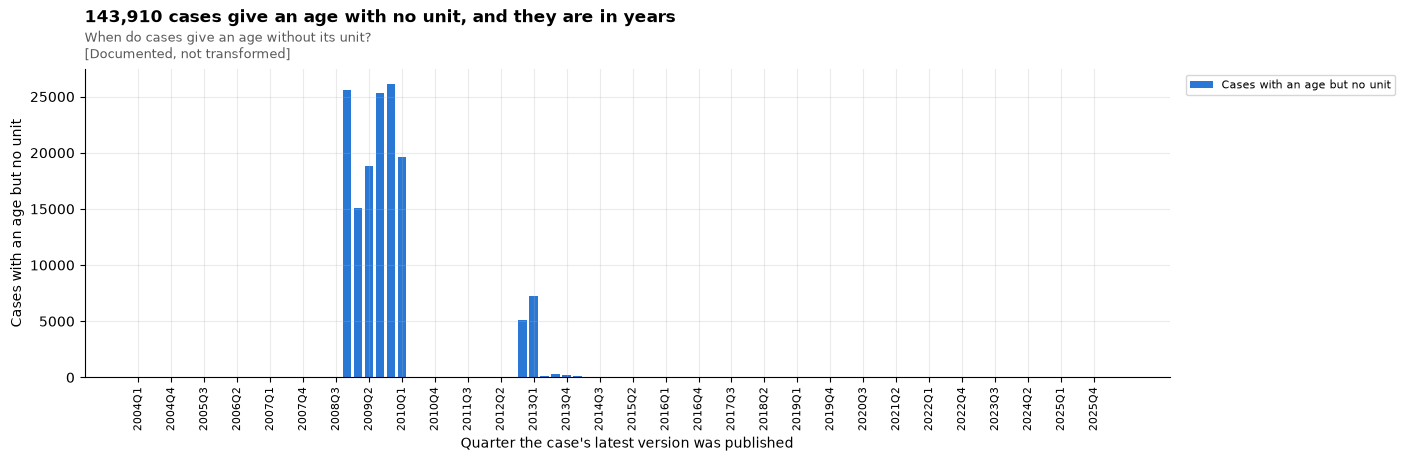

143,910 cases give an age but no unit, most of them published in AERS's last years and around the switch to FAERS, so a count that needs the unit leaves them without an age. Where another version of the same case gives the same number with a unit, it is years for 99% of 5,211 cases, and the numbers are spread like ages in years, so Open Altio reads them as years.
notebooks/out/cards/07_demographics_units.json


In [19]:
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import plot_card, write_cards

cards = compute_cards(
    con, ["sex_not_specified_for_empty", "ages_without_a_unit", "european_union_for_member_state"]
)
for card in cards:
    plot_card(card)
print(write_cards(cards, "07_demographics_units"))